# STEP 18 — Downloaded Saf Kabala Document Ingestion

Primary input document:

data/raw/deed_samples/সাফ-কবলা.pdf

Goals:

1. Verify the PDF file
2. Inspect page count
3. Check whether machine-readable text exists
4. Measure text availability page by page
5. Preserve the original raw document without modification

In [1]:
from pathlib import Path

PROJECT_ROOT = Path(r"D:\BhumiGuard-BD")

SAF_KABALA_PDF = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "deed_samples"
    / "সাফ-কবলা.pdf"
)

print("PDF path:")
print(SAF_KABALA_PDF)

print("\nExists:", SAF_KABALA_PDF.exists())

PDF path:
D:\BhumiGuard-BD\data\raw\deed_samples\সাফ-কবলা.pdf

Exists: True


In [11]:
file_size_mb = (
    SAF_KABALA_PDF.stat().st_size
    / (1024 * 1024)
)

print(
    "File name:",
    SAF_KABALA_PDF.name
)

print(
    "File size (MB):",
    round(file_size_mb, 2)
)

print(
    "Extension:",
    SAF_KABALA_PDF.suffix.lower()
)

File name: সাফ-কবলা.pdf
File size (MB): 0.27
Extension: .pdf


In [4]:
%pip install pymupdf

   ---------------------------------------- 0.0/19.8 MB ? eta -:--:--
   - -------------------------------------- 0.8/19.8 MB 6.2 MB/s eta 0:00:04
   -- ------------------------------------- 1.0/19.8 MB 3.6 MB/s eta 0:00:06
   -- ------------------------------------- 1.3/19.8 MB 2.3 MB/s eta 0:00:09
   --- ------------------------------------ 1.8/19.8 MB 2.4 MB/s eta 0:00:08
   --- ------------------------------------ 1.8/19.8 MB 2.4 MB/s eta 0:00:08
   ----- ---------------------------------- 2.6/19.8 MB 2.2 MB/s eta 0:00:08
   ----- ---------------------------------- 2.9/19.8 MB 2.1 MB/s eta 0:00:08
   ------ --------------------------------- 3.4/19.8 MB 2.1 MB/s eta 0:00:08
   ------- -------------------------------- 3.7/19.8 MB 2.1 MB/s eta 0:00:08
   ------- -------------------------------- 3.9/19.8 MB 2.0 MB/s eta 0:00:08
   -------- ------------------------------- 4.2/19.8 MB 1.8 MB/s eta 0:00:09
   -------- ------------------------------- 4.5/19.8 MB 1.9 MB/s eta 0:00:08
   ---


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
try:
    import fitz
    print("PyMuPDF: READY")

except ModuleNotFoundError:
    print("PyMuPDF is not installed.")

ImportError: DLL load failed while importing _extra: The specified module could not be found.

In [7]:
%pip install pypdf

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
from pypdf import PdfReader

print("pypdf import: PASS")

pypdf import: PASS


In [9]:
from pathlib import Path

PROJECT_ROOT = Path(r"D:\BhumiGuard-BD")

SAF_KABALA_PDF = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "deed_samples"
    / "সাফ-কবলা.pdf"
)

print("Exists:", SAF_KABALA_PDF.exists())

Exists: True


In [10]:
pdf_reader = PdfReader(
    str(SAF_KABALA_PDF)
)

page_count = len(
    pdf_reader.pages
)

print(
    "PDF opened: True"
)

print(
    "Page count:",
    page_count
)

PDF opened: True
Page count: 17


In [12]:
page_text_stats = []

for page_index, page in enumerate(
    pdf_reader.pages,
    start=1
):

    try:
        text = page.extract_text() or ""

        char_count = len(
            text.strip()
        )

        extraction_error = False

    except Exception:
        char_count = 0
        extraction_error = True

    page_text_stats.append({
        "page":
            page_index,

        "character_count":
            char_count,

        "has_text":
            char_count > 0,

        "extraction_error":
            extraction_error
    })

In [13]:
import pandas as pd

page_text_df = pd.DataFrame(
    page_text_stats
)

page_text_df

,page,character_count,has_text,extraction_error
0,1,664,True,False
1,2,498,True,False
2,3,449,True,False
3,4,454,True,False
4,5,446,True,False
5,6,747,True,False
6,7,1555,True,False
7,8,1728,True,False
8,9,1847,True,False
9,10,2396,True,False


In [14]:
extraction_errors = int(
    page_text_df[
        "extraction_error"
    ].sum()
)

print(
    "Extraction errors:",
    extraction_errors
)

Extraction errors: 0


In [15]:
pages_with_text = int(
    page_text_df[
        "has_text"
    ].sum()
)

pages_without_text = int(
    (
        ~page_text_df[
            "has_text"
        ]
    ).sum()
)

total_characters = int(
    page_text_df[
        "character_count"
    ].sum()
)

print(
    "Total pages:",
    page_count
)

print(
    "Pages with extractable text:",
    pages_with_text
)

print(
    "Pages without extractable text:",
    pages_without_text
)

print(
    "Total extracted characters:",
    total_characters
)

Total pages: 17
Pages with extractable text: 17
Pages without extractable text: 0
Total extracted characters: 18470


In [16]:
print(
    "Minimum characters/page:",
    page_text_df[
        "character_count"
    ].min()
)

print(
    "Maximum characters/page:",
    page_text_df[
        "character_count"
    ].max()
)

print(
    "Average characters/page:",
    round(
        page_text_df[
            "character_count"
        ].mean(),
        2
    )
)

Minimum characters/page: 305
Maximum characters/page: 2396
Average characters/page: 1086.47


In [17]:
text_page_ratio = (
    pages_with_text
    / page_count
)

if (
    text_page_ratio >= 0.8
    and total_characters > 1000
):
    pdf_text_status = (
        "TEXT_RICH"
    )

elif pages_with_text > 0:
    pdf_text_status = (
        "MIXED_TEXT_AND_IMAGE"
    )

else:
    pdf_text_status = (
        "IMAGE_ONLY_OR_SCANNED"
    )

print(
    "PDF text status:",
    pdf_text_status
)

PDF text status: TEXT_RICH


In [18]:
low_text_pages = page_text_df[
    page_text_df[
        "character_count"
    ] < 50
]

print(
    "Pages with < 50 characters:",
    len(low_text_pages)
)

if len(low_text_pages) > 0:
    display(low_text_pages)

Pages with < 50 characters: 0


In [19]:
first_page_text = (
    pdf_reader.pages[0]
    .extract_text()
    or ""
)

print(
    first_page_text[:500]
)

“বিসবিল্লাবির রিিাবির রবিি” 
ক্রমিক নং বমি নং দমিি নং 
 
১।  সাি-ররবিবি অবিসসর িাি :  ……… সাি-ররবিবি অবিস, ……..। 
২।  দবিসির সার সংসেপ  : 
দবিসির প্রকৃবি রিৌিার িাি বসটি কসপপাসরশি/রপৌরসভা/ইউবিয়ি থািা/উপসিিা রিিা  
সাি কিিা     
 
িস্তান্তবরি সম্পবির পবরিাি রেণী মূল্য অংসক ও কথায় 
……. আিাবসক এিাকার 
…… িং রসক্টসরর ….. িং 
ররাসের …. িং প্লসের /……  
কাঠা িা …… অযুিাংশ ভুবির 
আনুপাবিক িাসর অবিভক্ত ও 
অবিবিি ……..  অযুিাংশ ভূবি 
এিং রিাে ভূবির উপর বিবিপি 
“………” িািীয় ……. 
িিা বিবশষ্ট আিাবসক ইিারসির 
…


In [20]:
print("STEP 18A SUMMARY")
print("----------------")

print(
    "Saf Kabala PDF exists:",
    SAF_KABALA_PDF.exists()
)

print(
    "File size MB:",
    round(file_size_mb, 2)
)

print(
    "PDF pages:",
    page_count
)

print(
    "Pages with text:",
    pages_with_text
)

print(
    "Pages without text:",
    pages_without_text
)

print(
    "Extraction errors:",
    extraction_errors
)

print(
    "Total extracted characters:",
    total_characters
)

print(
    "PDF text status:",
    pdf_text_status
)

print(
    "Low-text pages:",
    len(low_text_pages)
)

print(
    "\nSaf Kabala PDF Ingestion: READY"
)

STEP 18A SUMMARY
----------------
Saf Kabala PDF exists: True
File size MB: 0.27
PDF pages: 17
Pages with text: 17
Pages without text: 0
Extraction errors: 0
Total extracted characters: 18470
PDF text status: TEXT_RICH
Low-text pages: 0

Saf Kabala PDF Ingestion: READY


# STEP 18B — Saf Kabala Page Rendering

The PDF contains an extractable text layer, but the Bengali text is
corrupted because of font/character encoding.

Therefore, BhumiGuard will not trust the extracted text directly.

Pipeline:

PDF
↓
Page image
↓
Visual quality check
↓
OCR
↓
Structured field extraction

In [21]:
%pip install pypdfium2

   ---------------------------------------- 0.0/3.9 MB ? eta -:--:--
   ----- ---------------------------------- 0.5/3.9 MB 9.9 MB/s eta 0:00:01
   ---------- ----------------------------- 1.0/3.9 MB 2.1 MB/s eta 0:00:02
   --------------- ------------------------ 1.6/3.9 MB 2.3 MB/s eta 0:00:02
   ------------------ --------------------- 1.8/3.9 MB 2.1 MB/s eta 0:00:02
   --------------------- ------------------ 2.1/3.9 MB 2.2 MB/s eta 0:00:01
   -------------------------- ------------- 2.6/3.9 MB 2.1 MB/s eta 0:00:01
   ----------------------------- ---------- 2.9/3.9 MB 2.0 MB/s eta 0:00:01
   ---------------------------------- ----- 3.4/3.9 MB 2.0 MB/s eta 0:00:01
   ------------------------------------- -- 3.7/3.9 MB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 3.9/3.9 MB 1.9 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
import pypdfium2 as pdfium

print("pypdfium2 import: PASS")

pypdfium2 import: PASS


In [23]:
pdf_render_doc = pdfium.PdfDocument(
    str(SAF_KABALA_PDF)
)

print(
    "Rendered PDF pages:",
    len(pdf_render_doc)
)

Rendered PDF pages: 17


In [24]:
page = pdf_render_doc[0]

bitmap = page.render(
    scale=2.0
)

page1_image = bitmap.to_pil()

print(
    "Page 1 image size:",
    page1_image.size
)

print(
    "Image mode:",
    page1_image.mode
)

Page 1 image size: (1224, 1584)
Image mode: RGB


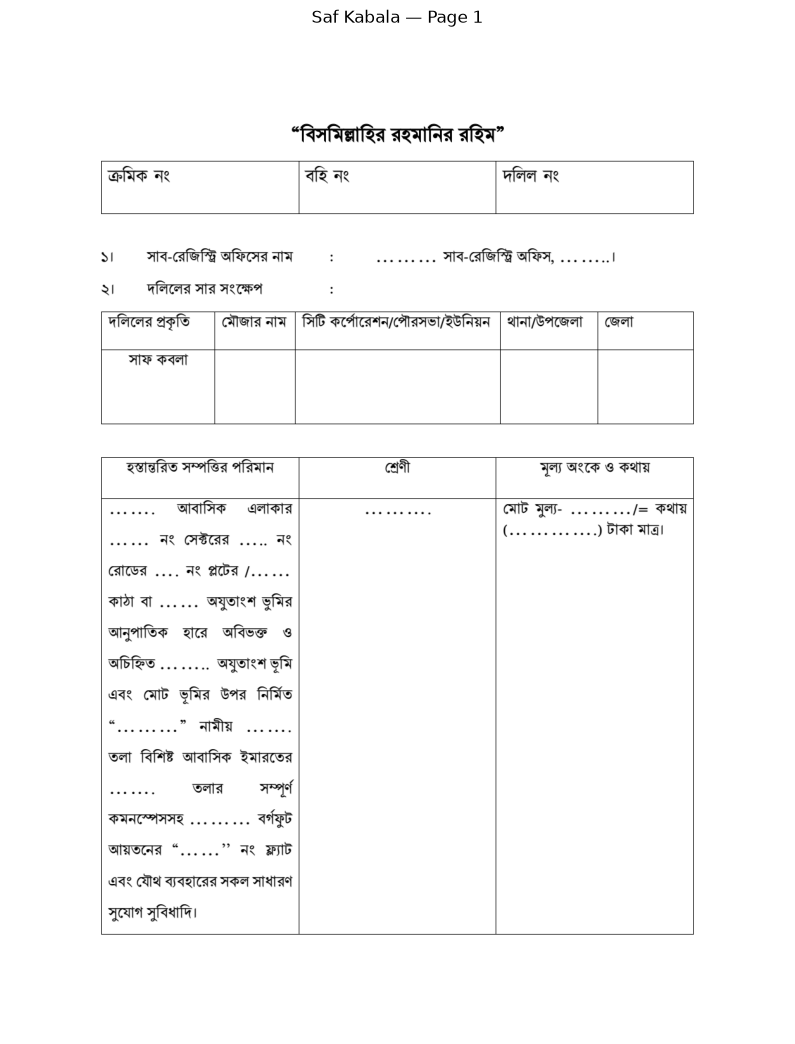

In [25]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(10, 14)
)

plt.imshow(
    page1_image
)

plt.axis("off")
plt.title(
    "Saf Kabala — Page 1"
)

plt.show()

In [26]:
rendered_pages = []

for page_number in range(3):

    page = pdf_render_doc[
        page_number
    ]

    bitmap = page.render(
        scale=2.0
    )

    image = bitmap.to_pil()

    rendered_pages.append(
        image
    )

print(
    "Pages rendered:",
    len(rendered_pages)
)

Pages rendered: 3


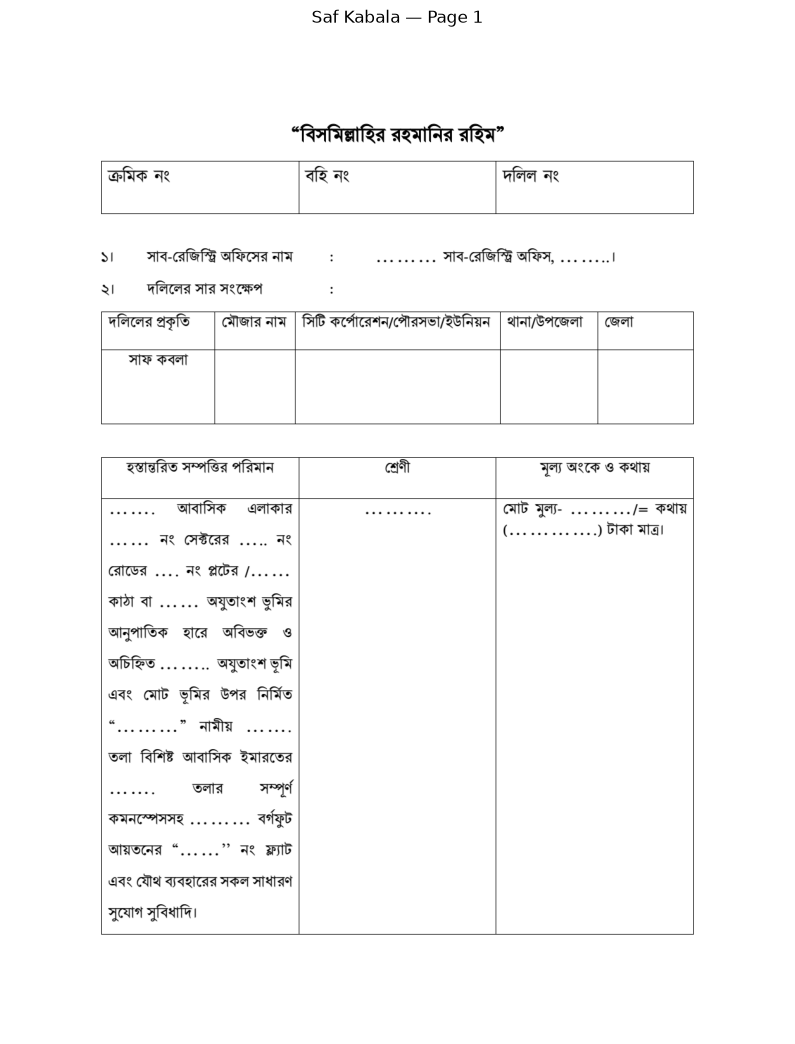

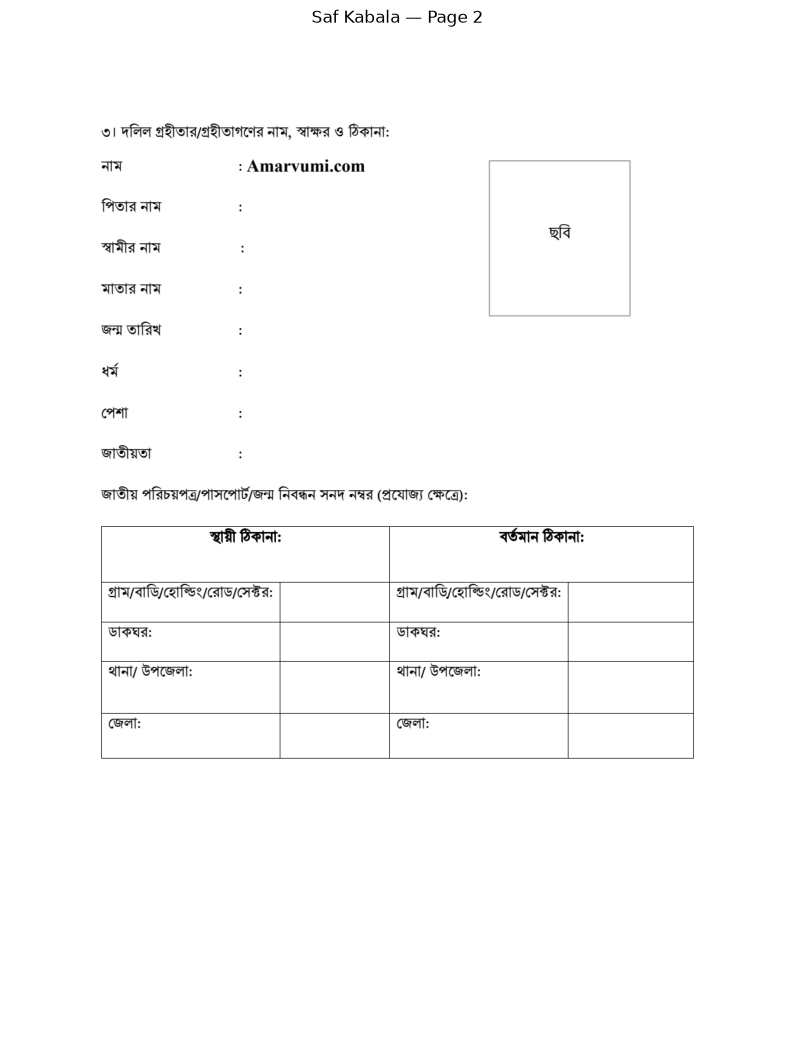

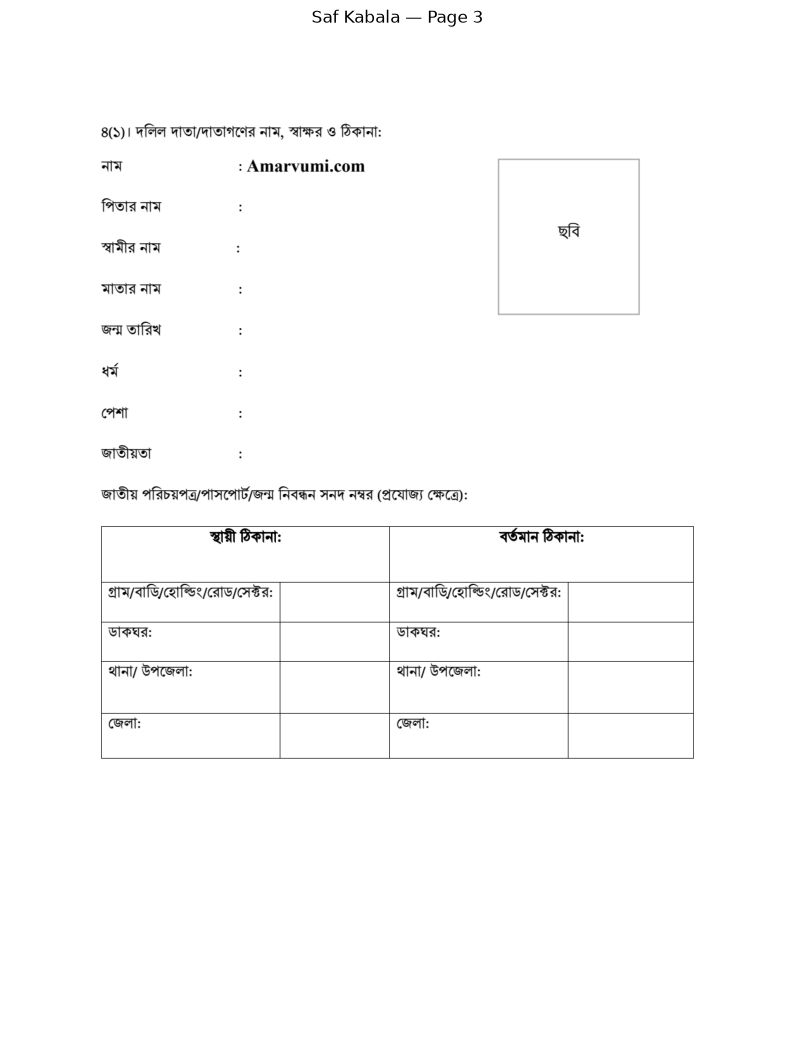

In [27]:
for i, image in enumerate(
    rendered_pages,
    start=1
):

    plt.figure(
        figsize=(10, 14)
    )

    plt.imshow(image)

    plt.axis("off")

    plt.title(
        f"Saf Kabala — Page {i}"
    )

    plt.show()

In [28]:
for i, image in enumerate(
    rendered_pages,
    start=1
):

    width, height = image.size

    print(
        f"Page {i}: "
        f"{width} x {height} | "
        f"Mode: {image.mode}"
    )

Page 1: 1224 x 1584 | Mode: RGB
Page 2: 1224 x 1584 | Mode: RGB
Page 3: 1224 x 1584 | Mode: RGB


In [29]:
text_layer_quality = (
    "TEXT_RICH_BUT_GARBLED"
)

ocr_required = True

print(
    "Text layer quality:",
    text_layer_quality
)

print(
    "OCR required:",
    ocr_required
)

Text layer quality: TEXT_RICH_BUT_GARBLED
OCR required: True


In [30]:
print("STEP 18B SUMMARY")
print("----------------")

print(
    "PDF pages:",
    len(pdf_render_doc)
)

print(
    "Pages test-rendered:",
    len(rendered_pages)
)

print(
    "Page 1 size:",
    page1_image.size
)

print(
    "Text layer:",
    text_layer_quality
)

print(
    "OCR required:",
    ocr_required
)

print(
    "\nSaf Kabala Rendering: READY"
)

STEP 18B SUMMARY
----------------
PDF pages: 17
Pages test-rendered: 3
Page 1 size: (1224, 1584)
Text layer: TEXT_RICH_BUT_GARBLED
OCR required: True

Saf Kabala Rendering: READY


# STEP 18C — Bengali OCR Baseline

Run Bengali OCR on the rendered Saf Kabala pages.

The rendered document is already clean and readable, so the first
baseline will use the original rendered page without image enhancement.

OCR language:

- Bengali
- English where necessary

In [33]:
import shutil

tesseract_path = shutil.which(
    "tesseract"
)

print(
    "Tesseract path:",
    tesseract_path
)

print(
    "Tesseract installed:",
    tesseract_path is not None
)

Tesseract path: None
Tesseract installed: False


In [34]:
from pathlib import Path

tesseract_exe = Path(
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

print(
    "Tesseract executable exists:",
    tesseract_exe.exists()
)

print(
    "Path:",
    tesseract_exe
)

Tesseract executable exists: True
Path: C:\Program Files\Tesseract-OCR\tesseract.exe


In [35]:
%pip install pytesseract

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
import pytesseract

pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

print(
    "Tesseract version:",
    pytesseract.get_tesseract_version()
)

Tesseract version: 5.5.3.20260724


In [37]:
installed_languages = (
    pytesseract.get_languages(
        config=""
    )
)

print(
    "Installed languages:",
    installed_languages
)

print(
    "Bengali available:",
    "ben" in installed_languages
)

print(
    "English available:",
    "eng" in installed_languages
)

Installed languages: ['eng', 'osd']
Bengali available: False
English available: True


In [38]:
from pathlib import Path

PROJECT_ROOT = Path(r"D:\BhumiGuard-BD")

CUSTOM_TESSDATA = (
    PROJECT_ROOT
    / "tessdata"
)

CUSTOM_TESSDATA.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Custom tessdata folder:",
    CUSTOM_TESSDATA
)

print(
    "Exists:",
    CUSTOM_TESSDATA.exists()
)

Custom tessdata folder: D:\BhumiGuard-BD\tessdata
Exists: True


In [39]:
BEN_MODEL = (
    CUSTOM_TESSDATA
    / "ben.traineddata"
)

print(
    "Bengali model exists:",
    BEN_MODEL.exists()
)

print(
    "Model size MB:",
    round(
        BEN_MODEL.stat().st_size
        / (1024 * 1024),
        2
    )
    if BEN_MODEL.exists()
    else None
)

Bengali model exists: True
Model size MB: 0.82


In [40]:
ENG_MODEL = (
    CUSTOM_TESSDATA
    / "eng.traineddata"
)

print(
    "English model exists:",
    ENG_MODEL.exists()
)

English model exists: True


In [41]:
import pytesseract

pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

tessdata_config = (
    f'--tessdata-dir "{CUSTOM_TESSDATA}"'
)

print(tessdata_config)

--tessdata-dir "D:\BhumiGuard-BD\tessdata"


In [42]:
test_text = pytesseract.image_to_string(
    page1_image,
    lang="ben",
    config=(
        f'{tessdata_config} '
        '--psm 3'
    )
)

print(
    test_text[:1000]
)

TesseractError: (1, 'Error opening data file "D:\\BhumiGuard-BD\\tessdata"/ben.traineddata Please make sure the TESSDATA_PREFIX environment variable is set to your "tessdata" directory. Failed loading language \'ben\' Tesseract couldn\'t load any languages! Could not initialize tesseract.')

In [43]:
from pathlib import Path

CUSTOM_TESSDATA = Path(
    r"D:\BhumiGuard-BD\tessdata"
)

BEN_MODEL = (
    CUSTOM_TESSDATA
    / "ben.traineddata"
)

ENG_MODEL = (
    CUSTOM_TESSDATA
    / "eng.traineddata"
)

print(
    "Tessdata folder:",
    CUSTOM_TESSDATA.exists()
)

print(
    "Bengali model exists:",
    BEN_MODEL.exists()
)

print(
    "English model exists:",
    ENG_MODEL.exists()
)

if BEN_MODEL.exists():
    print(
        "Bengali model MB:",
        round(
            BEN_MODEL.stat().st_size
            / (1024 * 1024),
            2
        )
    )

if ENG_MODEL.exists():
    print(
        "English model MB:",
        round(
            ENG_MODEL.stat().st_size
            / (1024 * 1024),
            2
        )
    )

Tessdata folder: True
Bengali model exists: True
English model exists: True
Bengali model MB: 0.82
English model MB: 3.92


In [44]:
import os
import pytesseract

pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

os.environ[
    "TESSDATA_PREFIX"
] = str(CUSTOM_TESSDATA)

print(
    "TESSDATA_PREFIX:"
)

print(
    os.environ[
        "TESSDATA_PREFIX"
    ]
)

TESSDATA_PREFIX:
D:\BhumiGuard-BD\tessdata


In [45]:
custom_languages = (
    pytesseract.get_languages(
        config=""
    )
)

print(
    "Languages from custom tessdata:",
    custom_languages
)

print(
    "Bengali available:",
    "ben" in custom_languages
)

print(
    "English available:",
    "eng" in custom_languages
)

Languages from custom tessdata: ['ben', 'eng']
Bengali available: True
English available: True


In [46]:
test_text = (
    pytesseract.image_to_string(
        page1_image,
        lang="ben",
        config="--psm 3"
    )
)

print(
    test_text[:1200]
)

ক্রমিক নং

২। দলিলের সার সংক্ষেপ

১

দলিলের প্রকৃতি । মৌজার নাম

জেলো

সাফ কবলা

এবং যোথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।




In [47]:
page1_ocr_text = (
    pytesseract.image_to_string(
        page1_image,
        lang="ben+eng",
        config="--psm 3"
    )
)

print(
    page1_ocr_text[:1500]
)

ক্রমিক নং

২। দলিলের সার সংক্ষেপ

3!

দলিলের প্রকৃতি = | মৌজার নাম

জেলো

সাফ কবলা

এবং যোথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।




In [48]:
test_text = pytesseract.image_to_string(
    page1_image,
    lang="ben",
    config="--psm 3"
)

print(
    test_text[:1500]
)

ক্রমিক নং

২। দলিলের সার সংক্ষেপ

১

দলিলের প্রকৃতি । মৌজার নাম

জেলো

সাফ কবলা

এবং যোথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।




In [49]:
page1_ocr_text = pytesseract.image_to_string(
    page1_image,
    lang="ben+eng",
    config="--psm 3"
)

print(
    page1_ocr_text[:1500]
)

ক্রমিক নং

২। দলিলের সার সংক্ষেপ

3!

দলিলের প্রকৃতি = | মৌজার নাম

জেলো

সাফ কবলা

এবং যোথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।




In [50]:
ocr_modes = {
    "PSM3_AUTO": "--psm 3",
    "PSM4_COLUMNS": "--psm 4",
    "PSM6_BLOCK": "--psm 6",
}

ocr_mode_results = {}

for mode_name, config in ocr_modes.items():

    text = pytesseract.image_to_string(
        page1_image,
        lang="ben+eng",
        config=config
    )

    ocr_mode_results[mode_name] = text

    print(
        mode_name,
        "characters:",
        len(text.strip())
    )

PSM3_AUTO characters: 128
PSM4_COLUMNS characters: 129
PSM6_BLOCK characters: 259


In [51]:
for mode_name, text in ocr_mode_results.items():

    print("\n")
    print("=" * 60)
    print(mode_name)
    print("=" * 60)

    print(
        text[:1200]
    )



PSM3_AUTO
ক্রমিক নং

২। দলিলের সার সংক্ষেপ

3!

দলিলের প্রকৃতি = | মৌজার নাম

জেলো

সাফ কবলা

এবং যোথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।




PSM4_COLUMNS
ক্রমিক নং বহি নং দলিল নং
১. সাব-রেজিস্ট্র অফিসের নাম
২। দলিলের সার সংক্ষেপ

সাফ কবলা
এবং যোথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।




PSM6_BLOCK
২। দলিলের সার সংক্ষেপ :

cece. আবাসিক এলাকার মোট মুল্য- ........./- কথায়
কাঠা বা ...... অযুতাংশ ভূমির

আনুপাতিক হারে অবিভক্ত ও

এবং মোট ভূমির উপর নির্মিত

তলা বিশিষ্ট আবাসিক ইমারতের

কমনস্পেসসহ ......... বর্গফুট

এবং যোথ ব্যবহারের সকল সাধারণ

সুযোগ সুবিধাদি।



In [52]:
expected_keywords = [
    "দলিল",
    "সাফ",
    "কবলা",
    "মৌজা",
    "জেলা",
    "সম্পত্তি",
    "মূল্য",
]

keyword_results = []

for mode_name, text in ocr_mode_results.items():

    found = [
        keyword
        for keyword in expected_keywords
        if keyword in text
    ]

    keyword_results.append({
        "mode": mode_name,
        "keywords_found": len(found),
        "total_keywords": len(expected_keywords),
        "found_keywords": found
    })

keyword_results_df = pd.DataFrame(
    keyword_results
)

keyword_results_df

,mode,keywords_found,total_keywords,found_keywords
0,PSM3_AUTO,4,7,"[দলিল, সাফ, কবলা, মৌজা]"
1,PSM4_COLUMNS,3,7,"[দলিল, সাফ, কবলা]"
2,PSM6_BLOCK,1,7,[দলিল]


In [53]:
best_mode_row = (
    keyword_results_df
    .sort_values(
        "keywords_found",
        ascending=False
    )
    .iloc[0]
)

best_mode = best_mode_row["mode"]

best_ocr_text = (
    ocr_mode_results[
        best_mode
    ]
)

print(
    "Best mode:",
    best_mode
)

print(
    "Keywords found:",
    best_mode_row["keywords_found"],
    "/",
    best_mode_row["total_keywords"]
)

Best mode: PSM3_AUTO
Keywords found: 4 / 7


In [54]:
print("STEP 18C SUMMARY")
print("----------------")

print(
    "Bengali OCR available:",
    "ben" in custom_languages
)

print(
    "English OCR available:",
    "eng" in custom_languages
)

print(
    "OCR modes tested:",
    len(ocr_mode_results)
)

print(
    "Best baseline mode:",
    best_mode
)

print(
    "Keywords found:",
    best_mode_row[
        "keywords_found"
    ],
    "/",
    best_mode_row[
        "total_keywords"
    ]
)

print(
    "Best OCR characters:",
    len(
        best_ocr_text.strip()
    )
)

print(
    "\nSaf Kabala OCR Baseline: TESTED"
)

STEP 18C SUMMARY
----------------
Bengali OCR available: True
English OCR available: True
OCR modes tested: 3
Best baseline mode: PSM3_AUTO
Keywords found: 4 / 7
Best OCR characters: 128

Saf Kabala OCR Baseline: TESTED


In [55]:
page = pdf_render_doc[0]

bitmap_4x = page.render(
    scale=4.0
)

page1_4x = bitmap_4x.to_pil()

print(
    "2x size:",
    page1_image.size
)

print(
    "4x size:",
    page1_4x.size
)

2x size: (1224, 1584)
4x size: (2448, 3168)


In [56]:
from PIL import ImageOps

page1_gray = ImageOps.grayscale(
    page1_4x
)

page1_autocontrast = ImageOps.autocontrast(
    page1_gray
)

print(
    "RAW:",
    page1_4x.size,
    page1_4x.mode
)

print(
    "GRAY:",
    page1_gray.size,
    page1_gray.mode
)

print(
    "AUTOCONTRAST:",
    page1_autocontrast.size,
    page1_autocontrast.mode
)

RAW: (2448, 3168) RGB
GRAY: (2448, 3168) L
AUTOCONTRAST: (2448, 3168) L


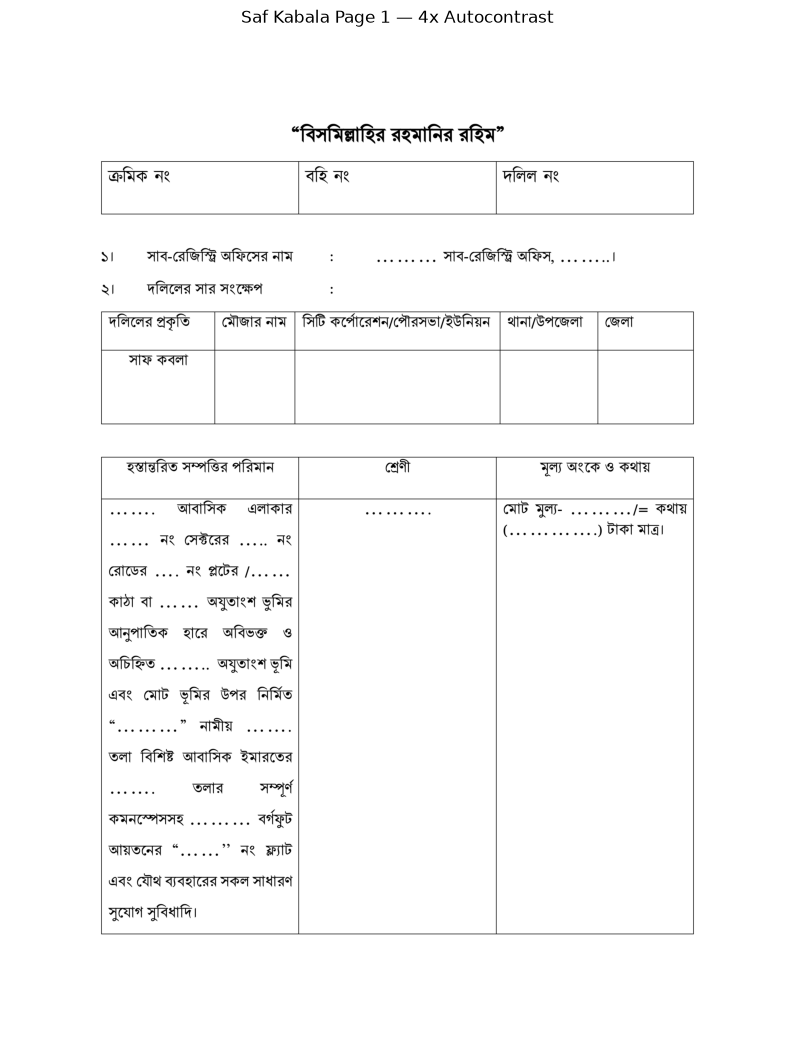

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 14))
plt.imshow(
    page1_autocontrast,
    cmap="gray"
)
plt.axis("off")
plt.title(
    "Saf Kabala Page 1 — 4x Autocontrast"
)
plt.show()

In [58]:
ocr_quality_keywords = [
    "দলিল",
    "সাফ",
    "কবলা",
    "মৌজা",
    "জেলা",
    "সম্পত্তি",
    "মূল্য",
    "ক্রমিক",
    "বহি",
    "রেজিস্ট্রি",
    "উপজেলা",
    "শ্রেণী",
]

In [59]:
ocr_images = {
    "RAW_4X": page1_4x,
    "GRAY_4X": page1_gray,
    "AUTOCONTRAST_4X": page1_autocontrast,
}

ocr_psm_modes = {
    "PSM3": "--psm 3",
    "PSM4": "--psm 4",
    "PSM6": "--psm 6",
}

In [60]:
preprocess_ocr_results = []

preprocess_ocr_texts = {}

for image_name, image in ocr_images.items():

    for psm_name, config in ocr_psm_modes.items():

        text = pytesseract.image_to_string(
            image,
            lang="ben+eng",
            config=config
        )

        key = f"{image_name}_{psm_name}"

        preprocess_ocr_texts[
            key
        ] = text

        found_keywords = [
            keyword
            for keyword in ocr_quality_keywords
            if keyword in text
        ]

        preprocess_ocr_results.append({
            "configuration":
                key,

            "characters":
                len(text.strip()),

            "keywords_found":
                len(found_keywords),

            "total_keywords":
                len(
                    ocr_quality_keywords
                ),

            "found_keywords":
                found_keywords,
        })

In [61]:
preprocess_results_df = pd.DataFrame(
    preprocess_ocr_results
)

preprocess_results_df = (
    preprocess_results_df
    .sort_values(
        [
            "keywords_found",
            "characters"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)

preprocess_results_df

,configuration,characters,keywords_found,total_keywords,found_keywords
0,RAW_4X_PSM4,269,12,12,"[দলিল, সাফ, কবলা, মৌজা, জেলা, সম্পত্তি, মূল্য,..."
1,GRAY_4X_PSM4,269,12,12,"[দলিল, সাফ, কবলা, মৌজা, জেলা, সম্পত্তি, মূল্য,..."
2,AUTOCONTRAST_4X_PSM4,269,12,12,"[দলিল, সাফ, কবলা, মৌজা, জেলা, সম্পত্তি, মূল্য,..."
3,RAW_4X_PSM3,240,8,12,"[দলিল, সাফ, কবলা, মৌজা, জেলা, সম্পত্তি, ক্রমিক..."
4,GRAY_4X_PSM3,240,8,12,"[দলিল, সাফ, কবলা, মৌজা, জেলা, সম্পত্তি, ক্রমিক..."
5,AUTOCONTRAST_4X_PSM3,240,8,12,"[দলিল, সাফ, কবলা, মৌজা, জেলা, সম্পত্তি, ক্রমিক..."
6,RAW_4X_PSM6,283,1,12,[দলিল]
7,GRAY_4X_PSM6,283,1,12,[দলিল]
8,AUTOCONTRAST_4X_PSM6,283,1,12,[দলিল]


In [62]:
top3_configs = (
    preprocess_results_df[
        "configuration"
    ]
    .head(3)
    .tolist()
)

print(
    "Top 3 configurations:"
)

for config_name in top3_configs:
    print(
        config_name
    )

Top 3 configurations:
RAW_4X_PSM4
GRAY_4X_PSM4
AUTOCONTRAST_4X_PSM4


In [63]:
for config_name in top3_configs:

    print("\n")
    print("=" * 70)

    print(
        config_name
    )

    print("=" * 70)

    print(
        preprocess_ocr_texts[
            config_name
        ][:1800]
    )



RAW_4X_PSM4
S| সাব-রেজিস্ট্রি অফিসের নাম
ny দলিলের সার সংক্ষেপ

দলিলের প্রকৃতি | মৌজার নাম | সিটি কর্পোরেশন/পৌরসভা/ইউনিয়ন | থানা/উপজেলা | জেলা

সাফ কবলা

ক্রমিক নং বহি নং দলিল নং

হস্তান্তরিত সম্পত্তির পরিমান শ্রেণী মূল্য অংকে ও কথায়

এবং যৌথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।




GRAY_4X_PSM4
S| সাব-রেজিস্ট্রি অফিসের নাম
ny দলিলের সার সংক্ষেপ

দলিলের প্রকৃতি | মৌজার নাম | সিটি কর্পোরেশন/পৌরসভা/ইউনিয়ন | থানা/উপজেলা | জেলা

সাফ কবলা

ক্রমিক নং বহি নং দলিল নং

হস্তান্তরিত সম্পত্তির পরিমান শ্রেণী মূল্য অংকে ও কথায়

এবং যৌথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।




AUTOCONTRAST_4X_PSM4
S| সাব-রেজিস্ট্রি অফিসের নাম
ny দলিলের সার সংক্ষেপ

দলিলের প্রকৃতি | মৌজার নাম | সিটি কর্পোরেশন/পৌরসভা/ইউনিয়ন | থানা/উপজেলা | জেলা

সাফ কবলা

ক্রমিক নং বহি নং দলিল নং

হস্তান্তরিত সম্পত্তির পরিমান শ্রেণী মূল্য অংকে ও কথায়

এবং যৌথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।




In [64]:
best_new_row = (
    preprocess_results_df.iloc[0]
)

print(
    "Previous 2x keyword score:",
    4,
    "/",
    7
)

print(
    "Previous 2x characters:",
    128
)

print(
    "\nBest 4x configuration:",
    best_new_row[
        "configuration"
    ]
)

print(
    "New keywords:",
    best_new_row[
        "keywords_found"
    ],
    "/",
    best_new_row[
        "total_keywords"
    ]
)

print(
    "New characters:",
    best_new_row[
        "characters"
    ]
)

Previous 2x keyword score: 4 / 7
Previous 2x characters: 128

Best 4x configuration: RAW_4X_PSM4
New keywords: 12 / 12
New characters: 269


In [65]:
width, height = (
    page1_autocontrast.size
)

header_crop = (
    page1_autocontrast.crop(
        (
            0,
            0,
            width,
            int(
                height * 0.45
            )
        )
    )
)

print(
    "Header crop size:",
    header_crop.size
)

Header crop size: (2448, 1425)


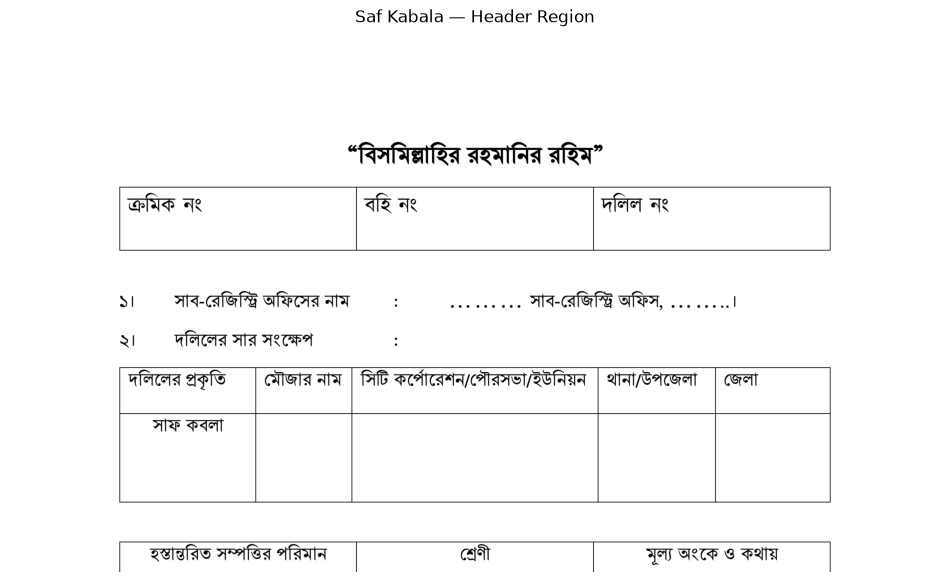

In [66]:
plt.figure(figsize=(12, 8))

plt.imshow(
    header_crop,
    cmap="gray"
)

plt.axis("off")

plt.title(
    "Saf Kabala — Header Region"
)

plt.show()

In [67]:
header_ocr_results = {}

for mode_name, config in {
    "PSM6_BLOCK": "--psm 6",
    "PSM11_SPARSE": "--psm 11",
}.items():

    text = pytesseract.image_to_string(
        header_crop,
        lang="ben+eng",
        config=config
    )

    header_ocr_results[
        mode_name
    ] = text

    print("\n")
    print("=" * 60)
    print(mode_name)
    print("=" * 60)

    print(
        text[:1500]
    )



PSM6_BLOCK
“বিসমিল্লাহির রহমানির রহিম”
QI দলিলের সার সংক্ষেপ :
হস্তান্তরিত সম্পত্তির পরিমান শ্রেণী মূল্য অংকে ও কথায়



PSM11_SPARSE
“বিসমিল্লাহির রহমানির রহিম”

ক্রমিক নং

বহি নং

দলিল নং

>|

সাব-রেজিস্ট্রি অফিসের নাম

সাব-রেজিন্ট্রি অফিস,

|

দলিলের সার সংক্ষেপ

দলিলের প্রকৃতি মৌজার নাম | সিটি কর্পোরেশন/পৌরসভা/ইউনিয়ন | থানা/উপজেলা | জেলা

সাফ কবলা

হস্তান্তরিত সম্পত্তির পরিমান

শ্রেণী

মূল্য অংকে ও কথায়



In [68]:
print("STEP 18D SUMMARY")
print("----------------")

print(
    "4x page size:",
    page1_4x.size
)

print(
    "Preprocessing variants:",
    len(ocr_images)
)

print(
    "PSM modes:",
    len(ocr_psm_modes)
)

print(
    "Configurations tested:",
    len(
        preprocess_results_df
    )
)

print(
    "Best configuration:",
    best_new_row[
        "configuration"
    ]
)

print(
    "Best keyword score:",
    best_new_row[
        "keywords_found"
    ],
    "/",
    best_new_row[
        "total_keywords"
    ]
)

print(
    "Best OCR characters:",
    best_new_row[
        "characters"
    ]
)

print(
    "Header OCR modes tested:",
    len(
        header_ocr_results
    )
)

print(
    "\nSaf Kabala OCR Preprocessing Benchmark: TESTED"
)

STEP 18D SUMMARY
----------------
4x page size: (2448, 3168)
Preprocessing variants: 3
PSM modes: 3
Configurations tested: 9
Best configuration: RAW_4X_PSM4
Best keyword score: 12 / 12
Best OCR characters: 269
Header OCR modes tested: 2

Saf Kabala OCR Preprocessing Benchmark: TESTED


# STEP 18E — Region-Aware OCR and Field Anchor Mapping

The full-page OCR recognizes the main Bengali field labels, but misses
large portions of text because the Saf Kabala form contains tables and
multiple layout regions.

This step:

1. Splits the page into overlapping horizontal regions
2. Runs OCR separately on each region
3. Compares regional OCR coverage
4. Identifies Saf Kabala field anchors

No transaction values are extracted yet.

In [69]:
def crop_by_ratio(
    image,
    left,
    top,
    right,
    bottom
):
    width, height = image.size

    return image.crop(
        (
            int(width * left),
            int(height * top),
            int(width * right),
            int(height * bottom),
        )
    )

In [70]:
page1_regions = {
    "REGION_1_HEADER":
        (0.00, 0.00, 1.00, 0.20),

    "REGION_2_SUMMARY":
        (0.00, 0.15, 1.00, 0.38),

    "REGION_3_PROPERTY":
        (0.00, 0.33, 1.00, 0.58),

    "REGION_4_DESCRIPTION":
        (0.00, 0.53, 1.00, 0.78),

    "REGION_5_LOWER":
        (0.00, 0.73, 1.00, 1.00),
}

In [71]:
region_images = {}

for region_name, coords in page1_regions.items():

    region_images[region_name] = (
        crop_by_ratio(
            page1_4x,
            *coords
        )
    )

print(
    "Regions created:",
    len(region_images)
)

Regions created: 5


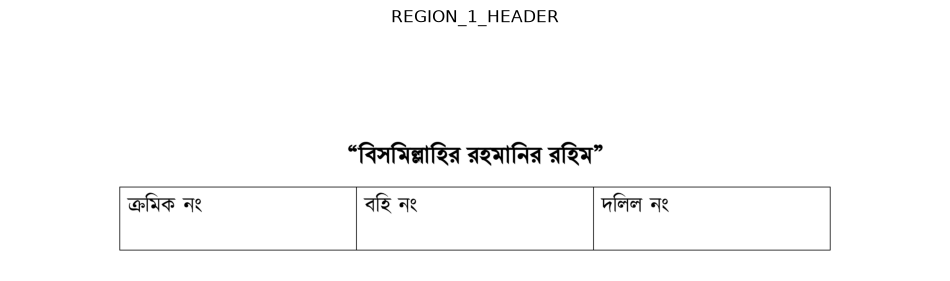

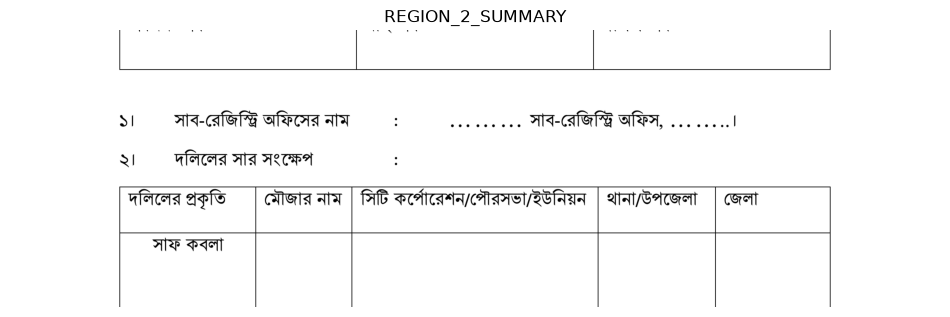

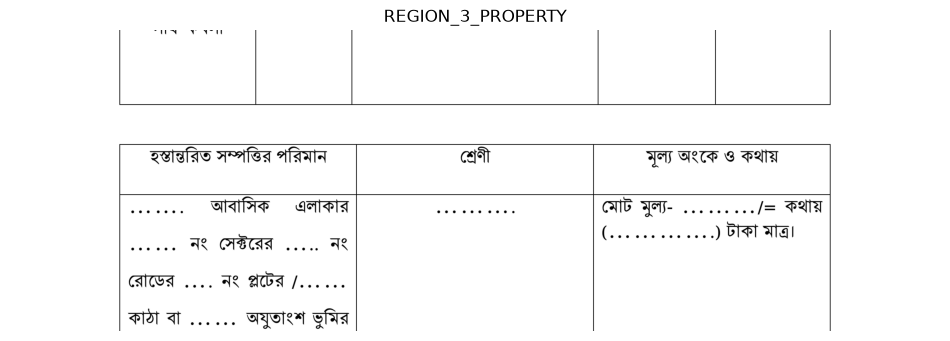

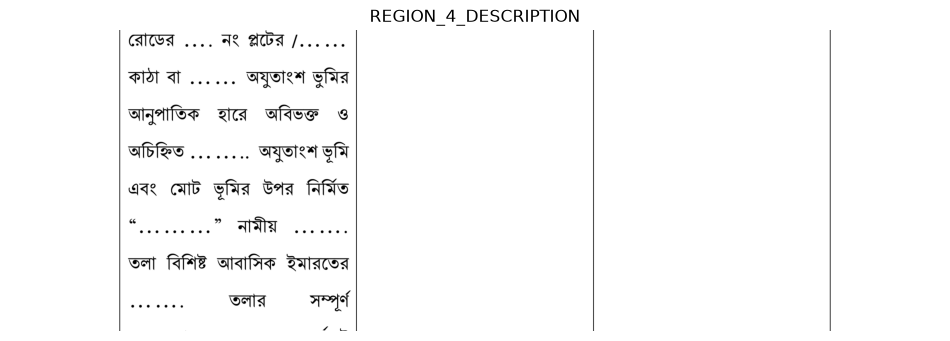

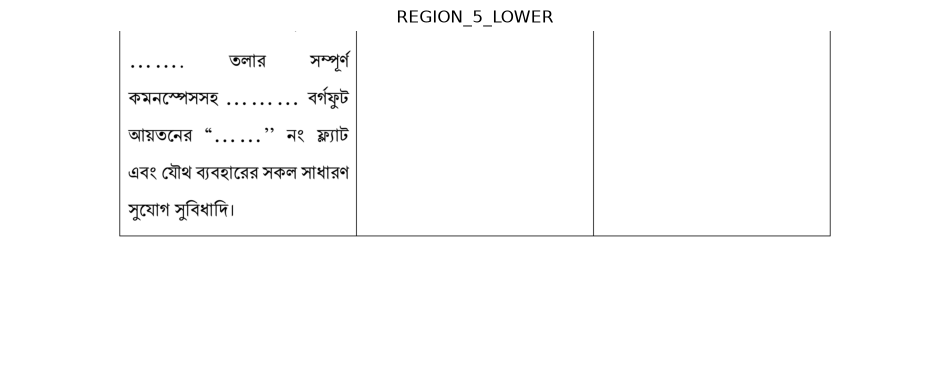

In [72]:
for region_name, image in region_images.items():

    plt.figure(
        figsize=(12, 5)
    )

    plt.imshow(image)

    plt.axis("off")

    plt.title(region_name)

    plt.show()

In [73]:
region_ocr_texts = {}

for region_name, image in region_images.items():

    text = pytesseract.image_to_string(
        image,
        lang="ben+eng",
        config="--psm 4"
    )

    region_ocr_texts[
        region_name
    ] = text

    print(
        region_name,
        "characters:",
        len(text.strip())
    )

REGION_1_HEADER characters: 9
REGION_2_SUMMARY characters: 168
REGION_3_PROPERTY characters: 216
REGION_4_DESCRIPTION characters: 129
REGION_5_LOWER characters: 104


In [74]:
for region_name, text in region_ocr_texts.items():

    print("\n")
    print("=" * 70)
    print(region_name)
    print("=" * 70)

    print(
        text[:2000]
    )



REGION_1_HEADER
ক্রমিক নং




REGION_2_SUMMARY
S| সাব-রেজিস্ট্রি অফিসের নাম
ny দলিলের সার সংক্ষেপ

eee ০৩০০৯৯

eee cee coe

দলিলের প্রকৃতি = | মৌজার নাম | সিটি কর্পোরেশন/পৌরসভা/ইউনিয়ন | থানা/উপজেলা | জেলা

সাফ কবলা



REGION_3_PROPERTY
২

হস্তান্তরিত সম্পত্তির পরিমান শ্রেণী মূল্য অংকে ও কথায়
১০০ ০০০০ আবাসিক এলাকার ১০০ ০০০০০০, মোট মুল্য- ... ... .../- কথায়
রা © সেক্টরের . ₹ (২... eee.) টাকা WGI
রোডের .... নং প্লটের /......
কাঠা বা... অযুতাংশ ভুমির



REGION_4_DESCRIPTION
কাঠা বা... অযুতাংশ ভুমির
আনুপাতিক হারে অবিভক্ত ও
OIRO ... ..... অযুতাংশ ভূমি
এবং মোট ভূমির উপর নির্মিত
১১০০০০০০৩ " নামীয় ....০০,



REGION_5_LOWER
কমনস্পেসসহ ... ... ee বর্গফুট
আয়তনের “...,.. » নং ফ্ল্যাট

এবং যৌথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।




In [75]:
combined_region_ocr = "\n".join(
    region_ocr_texts.values()
)

print(
    "Full-page OCR characters:",
    len(
        best_ocr_text.strip()
    )
)

print(
    "Combined regional OCR characters:",
    len(
        combined_region_ocr.strip()
    )
)

Full-page OCR characters: 128
Combined regional OCR characters: 635


In [76]:
page1_field_anchors = [
    "ক্রমিক",
    "বহি",
    "দলিল নং",
    "সাব-রেজিস্ট্রি অফিসের নাম",
    "দলিলের সার সংক্ষেপ",
    "দলিলের প্রকৃতি",
    "মৌজার নাম",
    "সিটি কর্পোরেশন",
    "পৌরসভা",
    "ইউনিয়ন",
    "থানা",
    "উপজেলা",
    "জেলা",
    "সাফ কবলা",
    "হস্তান্তরিত সম্পত্তির পরিমান",
    "শ্রেণী",
    "মূল্য",
]

In [77]:
anchor_results = []

for anchor in page1_field_anchors:

    found = (
        anchor
        in combined_region_ocr
    )

    anchor_results.append({
        "anchor":
            anchor,

        "found":
            found
    })


anchor_results_df = pd.DataFrame(
    anchor_results
)

anchor_results_df

,anchor,found
0,ক্রমিক,True
1,বহি,False
2,দলিল নং,False
3,সাব-রেজিস্ট্রি অফিসের নাম,True
4,দলিলের সার সংক্ষেপ,True
5,দলিলের প্রকৃতি,True
6,মৌজার নাম,True
7,সিটি কর্পোরেশন,True
8,পৌরসভা,True
9,ইউনিয়ন,True


In [78]:
anchor_results = []

for anchor in page1_field_anchors:

    found = (
        anchor
        in combined_region_ocr
    )

    anchor_results.append({
        "anchor":
            anchor,

        "found":
            found
    })


anchor_results_df = pd.DataFrame(
    anchor_results
)

anchor_results_df

,anchor,found
0,ক্রমিক,True
1,বহি,False
2,দলিল নং,False
3,সাব-রেজিস্ট্রি অফিসের নাম,True
4,দলিলের সার সংক্ষেপ,True
5,দলিলের প্রকৃতি,True
6,মৌজার নাম,True
7,সিটি কর্পোরেশন,True
8,পৌরসভা,True
9,ইউনিয়ন,True


In [79]:
anchors_found = int(
    anchor_results_df[
        "found"
    ].sum()
)

anchors_total = len(
    anchor_results_df
)

print(
    "Anchors found:",
    anchors_found,
    "/",
    anchors_total
)

Anchors found: 15 / 17


In [80]:
anchor_region_results = []

for anchor in page1_field_anchors:

    found_regions = []

    for region_name, text in region_ocr_texts.items():

        if anchor in text:
            found_regions.append(
                region_name
            )

    anchor_region_results.append({
        "anchor":
            anchor,

        "regions":
            found_regions,

        "region_count":
            len(found_regions)
    })


anchor_region_df = pd.DataFrame(
    anchor_region_results
)

anchor_region_df

,anchor,regions,region_count
0,ক্রমিক,[REGION_1_HEADER],1
1,বহি,[],0
2,দলিল নং,[],0
3,সাব-রেজিস্ট্রি অফিসের নাম,[REGION_2_SUMMARY],1
4,দলিলের সার সংক্ষেপ,[REGION_2_SUMMARY],1
5,দলিলের প্রকৃতি,[REGION_2_SUMMARY],1
6,মৌজার নাম,[REGION_2_SUMMARY],1
7,সিটি কর্পোরেশন,[REGION_2_SUMMARY],1
8,পৌরসভা,[REGION_2_SUMMARY],1
9,ইউনিয়ন,[REGION_2_SUMMARY],1


In [81]:
missing_anchors = (
    anchor_results_df[
        anchor_results_df[
            "found"
        ] == False
    ]
)

print(
    "Missing anchors:",
    len(missing_anchors)
)

if len(missing_anchors) > 0:
    display(
        missing_anchors
    )

Missing anchors: 2


,anchor,found
1,বহি,False
2,দলিল নং,False


In [83]:
print("STEP 18E SUMMARY")
print("----------------")

print(
    "Page regions:",
    len(region_images)
)

print(
    "Full-page OCR characters:",
    len(
        best_ocr_text.strip()
    )
)

print(
    "Regional OCR characters:",
    len(
        combined_region_ocr.strip()
    )
)

print(
    "Field anchors:",
    anchors_total
)

print(
    "Anchors detected:",
    anchors_found
)

print(
    "Anchors missing:",
    anchors_total
    - anchors_found
)

print(
    "Region OCR method:",
    "RAW_4X_PSM4"
)

print(
    "\nSaf Kabala Region OCR: TESTED"
)

STEP 18E SUMMARY
----------------
Page regions: 5
Full-page OCR characters: 128
Regional OCR characters: 635
Field anchors: 17
Anchors detected: 15
Anchors missing: 2
Region OCR method: RAW_4X_PSM4

Saf Kabala Region OCR: TESTED


In [84]:
best_4x_config = (
    preprocess_results_df
    .iloc[0]["configuration"]
)

best_4x_ocr_text = (
    preprocess_ocr_texts[
        best_4x_config
    ]
)

print(
    "Best 4x configuration:",
    best_4x_config
)

print(
    "Best 4x characters:",
    len(best_4x_ocr_text.strip())
)

print(
    "Regional characters:",
    len(combined_region_ocr.strip())
)

Best 4x configuration: RAW_4X_PSM4
Best 4x characters: 269
Regional characters: 635


In [85]:
width, height = page1_4x.size

deed_header_crop = page1_4x.crop(
    (
        0,
        0,
        width,
        int(height * 0.15)
    )
)

print(
    "Header crop:",
    deed_header_crop.size
)

Header crop: (2448, 475)


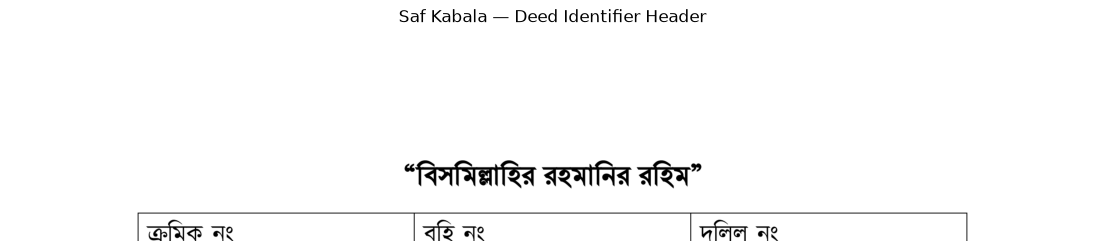

In [86]:
plt.figure(figsize=(14, 4))

plt.imshow(deed_header_crop)

plt.axis("off")

plt.title(
    "Saf Kabala — Deed Identifier Header"
)

plt.show()

In [87]:
header_configs = {
    "PSM4": "--psm 4",
    "PSM6": "--psm 6",
    "PSM7": "--psm 7",
    "PSM11": "--psm 11",
}

deed_header_ocr = {}

for mode, config in header_configs.items():

    text = pytesseract.image_to_string(
        deed_header_crop,
        lang="ben+eng",
        config=config
    )

    deed_header_ocr[
        mode
    ] = text

    print("\n", "=" * 50)
    print(mode)
    print("=" * 50)
    print(text)


PSM4
(ক্রমিক নং


PSM6
“বিসমিল্লাহির রহমানির রহিম”
ক্রমিক নং বতি নং দলিল নং


PSM7
ক্রমিক নং ৮ নস নি ae


PSM11
“বিসমিল্লাহির রহমানির রহিম”

(ক্রমিক নং

| af নং

| দলিল নং



In [88]:
header_targets = [
    "ক্রমিক",
    "বহি",
    "দলিল",
]

header_mode_results = []

for mode, text in deed_header_ocr.items():

    found = [
        term
        for term in header_targets
        if term in text
    ]

    header_mode_results.append({
        "mode": mode,
        "found_count": len(found),
        "found_terms": found,
        "characters": len(text.strip())
    })


header_mode_df = pd.DataFrame(
    header_mode_results
).sort_values(
    [
        "found_count",
        "characters"
    ],
    ascending=[
        False,
        False
    ]
)

header_mode_df

,mode,found_count,found_terms,characters
3,PSM11,2,"[ক্রমিক, দলিল]",59
1,PSM6,2,"[ক্রমিক, দলিল]",52
2,PSM7,1,[ক্রমিক],20
0,PSM4,1,[ক্রমিক],10


# STEP 18F — 17-Page Saf Kabala Structure Mapping

Map the semantic structure of the downloaded 17-page Saf Kabala form.

This step does not extract transaction values.

Goals:

- OCR all pages using the validated 4x + PSM4 baseline
- identify likely document sections
- measure section-anchor evidence
- prepare page targets for later field extraction

In [89]:
all_page_ocr = []

for page_index in range(
    len(pdf_render_doc)
):

    page = pdf_render_doc[
        page_index
    ]

    bitmap = page.render(
        scale=4.0
    )

    image = bitmap.to_pil()

    text = pytesseract.image_to_string(
        image,
        lang="ben+eng",
        config="--psm 4"
    )

    all_page_ocr.append({
        "page":
            page_index + 1,

        "characters":
            len(text.strip()),

        "text":
            text
    })

    print(
        f"Page {page_index + 1:02d} "
        f"completed | "
        f"{len(text.strip())} chars"
    )

Page 01 completed | 269 chars
Page 02 completed | 303 chars
Page 03 completed | 299 chars
Page 04 completed | 227 chars
Page 05 completed | 299 chars
Page 06 completed | 586 chars
Page 07 completed | 1541 chars
Page 08 completed | 1079 chars
Page 09 completed | 1297 chars
Page 10 completed | 1893 chars
Page 11 completed | 1791 chars
Page 12 completed | 1198 chars
Page 13 completed | 1080 chars
Page 14 completed | 611 chars
Page 15 completed | 299 chars
Page 16 completed | 1707 chars
Page 17 completed | 540 chars


In [90]:
page_ocr_stats_df = pd.DataFrame(
    [
        {
            "page": item["page"],
            "characters":
                item["characters"]
        }
        for item in all_page_ocr
    ]
)

page_ocr_stats_df

,page,characters
0,1,269
1,2,303
2,3,299
3,4,227
4,5,299
5,6,586
6,7,1541
7,8,1079
8,9,1297
9,10,1893


In [91]:
print(
    "Pages OCRed:",
    len(all_page_ocr)
)

print(
    "Total OCR characters:",
    page_ocr_stats_df[
        "characters"
    ].sum()
)

print(
    "Minimum/page:",
    page_ocr_stats_df[
        "characters"
    ].min()
)

print(
    "Maximum/page:",
    page_ocr_stats_df[
        "characters"
    ].max()
)

Pages OCRed: 17
Total OCR characters: 15019
Minimum/page: 227
Maximum/page: 1893


In [92]:
section_anchors = {

    "SUMMARY": [
        "সার সংক্ষেপ",
        "দলিলের প্রকৃতি",
        "মৌজার নাম",
        "সাফ কবলা",
    ],

    "BUYER": [
        "ক্রেতা",
        "জাতীয় পরিচয়",
        "ঠিকানা",
    ],

    "SELLER": [
        "বিক্রেতা",
        "জাতীয় পরিচয়",
        "ঠিকানা",
    ],

    "POWER_OF_ATTORNEY": [
        "পাওয়ার",
        "আমমোক্তার",
        "মোক্তার",
    ],

    "OWNERSHIP_HISTORY": [
        "মালিকানা",
        "২৫ বছর",
        "পূর্ববর্তী",
        "দলিল",
    ],

    "SHARE_EXECUTION": [
        "অংশ",
        "তারিখ",
        "সম্পাদন",
    ],

    "PROPERTY_SCHEDULE": [
        "তফসিল",
        "দাগ",
        "খতিয়ান",
        "মৌজা",
    ],

    "BOUNDARY": [
        "চৌহদ্দি",
        "উত্তর",
        "দক্ষিণ",
        "পূর্ব",
        "পশ্চিম",
    ],

    "PAYMENT": [
        "মূল্য",
        "পরিশোধ",
        "টাকা",
    ],

    "AFFIDAVIT": [
        "হলফনামা",
        "ঘোষণা",
        "বন্ধক",
        "বায়না",
    ],
}

In [93]:
section_mapping_results = []

for page_item in all_page_ocr:

    text = page_item["text"]

    for section, anchors in (
        section_anchors.items()
    ):

        matched = [
            anchor
            for anchor in anchors
            if anchor in text
        ]

        section_mapping_results.append({
            "page":
                page_item["page"],

            "section":
                section,

            "score":
                len(matched),

            "anchors_found":
                matched
        })


section_mapping_df = pd.DataFrame(
    section_mapping_results
)

In [94]:
best_sections_per_page = (
    section_mapping_df
    .sort_values(
        [
            "page",
            "score"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "page"
    )
    .head(3)
)

best_sections_per_page[
    best_sections_per_page[
        "score"
    ] > 0
]

,page,section,score,anchors_found
0,1,SUMMARY,4,"[সার সংক্ষেপ, দলিলের প্রকৃতি, মৌজার নাম, সাফ ক..."
4,1,OWNERSHIP_HISTORY,1,[দলিল]
6,1,PROPERTY_SCHEDULE,1,[মৌজা]
11,2,BUYER,2,"[জাতীয় পরিচয়, ঠিকানা]"
12,2,SELLER,2,"[জাতীয় পরিচয়, ঠিকানা]"
14,2,OWNERSHIP_HISTORY,1,[দলিল]
21,3,BUYER,2,"[জাতীয় পরিচয়, ঠিকানা]"
22,3,SELLER,2,"[জাতীয় পরিচয়, ঠিকানা]"
24,3,OWNERSHIP_HISTORY,1,[দলিল]
31,4,BUYER,1,[ঠিকানা]


In [95]:
best_pages_per_section = (
    section_mapping_df
    .sort_values(
        [
            "section",
            "score"
        ],
        ascending=[
            True,
            False
        ]
    )
    .groupby(
        "section"
    )
    .head(3)
)

best_pages_per_section[
    best_pages_per_section[
        "score"
    ] > 0
]

,page,section,score,anchors_found
159,16,AFFIDAVIT,4,"[হলফনামা, ঘোষণা, বন্ধক, বায়না]"
109,11,AFFIDAVIT,2,"[ঘোষণা, বায়না]"
117,12,BOUNDARY,2,"[উত্তর, দক্ষিণ]"
97,10,BOUNDARY,1,[পূর্ব]
107,11,BOUNDARY,1,[পূর্ব]
11,2,BUYER,2,"[জাতীয় পরিচয়, ঠিকানা]"
21,3,BUYER,2,"[জাতীয় পরিচয়, ঠিকানা]"
41,5,BUYER,2,"[জাতীয় পরিচয়, ঠিকানা]"
64,7,OWNERSHIP_HISTORY,3,"[মালিকানা, ২৫ বছর, দলিল]"
104,11,OWNERSHIP_HISTORY,2,"[মালিকানা, দলিল]"


In [96]:
strong_section_matches = (
    section_mapping_df[
        section_mapping_df[
            "score"
        ] >= 2
    ]
    .sort_values(
        [
            "page",
            "score"
        ],
        ascending=[
            True,
            False
        ]
    )
)

strong_section_matches

,page,section,score,anchors_found
0,1,SUMMARY,4,"[সার সংক্ষেপ, দলিলের প্রকৃতি, মৌজার নাম, সাফ ক..."
11,2,BUYER,2,"[জাতীয় পরিচয়, ঠিকানা]"
12,2,SELLER,2,"[জাতীয় পরিচয়, ঠিকানা]"
21,3,BUYER,2,"[জাতীয় পরিচয়, ঠিকানা]"
22,3,SELLER,2,"[জাতীয় পরিচয়, ঠিকানা]"
41,5,BUYER,2,"[জাতীয় পরিচয়, ঠিকানা]"
42,5,SELLER,2,"[জাতীয় পরিচয়, ঠিকানা]"
64,7,OWNERSHIP_HISTORY,3,"[মালিকানা, ২৫ বছর, দলিল]"
68,7,PAYMENT,2,"[পরিশোধ, টাকা]"
85,9,SHARE_EXECUTION,3,"[অংশ, তারিখ, সম্পাদন]"


In [97]:
page_structure_map = []

for page_number in range(
    1,
    len(all_page_ocr) + 1
):

    matches = (
        strong_section_matches[
            strong_section_matches[
                "page"
            ] == page_number
        ]
    )

    sections = (
        matches[
            "section"
        ].tolist()
    )

    page_structure_map.append({
        "page":
            page_number,

        "sections":
            sections,

        "ocr_characters":
            all_page_ocr[
                page_number - 1
            ][
                "characters"
            ]
    })


page_structure_df = pd.DataFrame(
    page_structure_map
)

page_structure_df

,page,sections,ocr_characters
0,1,[SUMMARY],269
1,2,"[BUYER, SELLER]",303
2,3,"[BUYER, SELLER]",299
3,4,[],227
4,5,"[BUYER, SELLER]",299
5,6,[],586
6,7,"[OWNERSHIP_HISTORY, PAYMENT]",1541
7,8,[],1079
8,9,"[SHARE_EXECUTION, PAYMENT]",1297
9,10,"[PAYMENT, SHARE_EXECUTION]",1893


In [98]:
detected_sections = set(
    strong_section_matches[
        "section"
    ]
)

all_sections = set(
    section_anchors.keys()
)

missing_sections = (
    all_sections
    - detected_sections
)

print(
    "Defined sections:",
    len(all_sections)
)

print(
    "Detected sections:",
    len(detected_sections)
)

print(
    "Missing sections:",
    sorted(
        missing_sections
    )
)

Defined sections: 10
Detected sections: 9
Missing sections: ['POWER_OF_ATTORNEY']


In [99]:
print("STEP 18F SUMMARY")
print("----------------")

print(
    "Pages OCRed:",
    len(all_page_ocr)
)

print(
    "Total OCR characters:",
    int(
        page_ocr_stats_df[
            "characters"
        ].sum()
    )
)

print(
    "Document sections defined:",
    len(all_sections)
)

print(
    "Sections detected:",
    len(detected_sections)
)

print(
    "Sections missing:",
    len(missing_sections)
)

print(
    "Strong page-section matches:",
    len(
        strong_section_matches
    )
)

print(
    "\nSaf Kabala Structure Mapping: TESTED"
)

STEP 18F SUMMARY
----------------
Pages OCRed: 17
Total OCR characters: 15019
Document sections defined: 10
Sections detected: 9
Sections missing: 1
Strong page-section matches: 22

Saf Kabala Structure Mapping: TESTED


# STEP 18G — Precise Section Anchor Refinement

Refine ambiguous Saf Kabala section mappings using distinctive
section-specific Bengali keywords.

This step avoids shared generic anchors such as:

- ঠিকানা
- জাতীয় পরিচয়
- তারিখ
- দলিল

and focuses on distinctive semantic terms before field extraction.

In [100]:
def get_page_ocr(page_number):
    return all_page_ocr[
        page_number - 1
    ]["text"]

In [101]:
print(
    "Page 1 chars:",
    len(get_page_ocr(1).strip())
)

print(
    "Page 16 chars:",
    len(get_page_ocr(16).strip())
)

Page 1 chars: 269
Page 16 chars: 1707


In [102]:
precise_section_terms = {

    "BUYER": [
        "ক্রেতা",
        "গ্রহীতা",
    ],

    "SELLER": [
        "বিক্রেতা",
        "দাতা",
    ],

    "POWER_OF_ATTORNEY": [
        "পাওয়ার অব অ্যাটর্নি",
        "পাওয়ার অব অ্যাটর্নি",
        "পাওয়ার",
        "আমমোক্তার",
        "মোক্তার",
    ],

    "OWNERSHIP_HISTORY": [
        "২৫ বছর",
        "মালিকানা",
        "মালিকানার",
    ],

    "PROPERTY_SCHEDULE": [
        "তফসিল",
        "খতিয়ান",
        "খতিয়ান",
        "দাগ",
    ],

    "BOUNDARY": [
        "চৌহদ্দি",
        "উত্তর",
        "দক্ষিণ",
        "পূর্ব",
        "পশ্চিম",
    ],

    "PAYMENT": [
        "পরিশোধ",
        "বায়না মূল্য",
        "বিক্রয় মূল্য",
        "মূল্য",
        "টাকা",
    ],

    "AFFIDAVIT": [
        "হলফনামা",
        "ঘোষণা",
        "বন্ধক",
        "বায়না",
    ],
}

In [104]:
precise_matches = []

for page_number in range(
    1,
    len(all_page_ocr) + 1
):

    text = get_page_ocr(
        page_number
    )

    for section, terms in (
        precise_section_terms.items()
    ):

        found_terms = [
            term
            for term in terms
            if term in text
        ]

        if found_terms:

            precise_matches.append({
                "page":
                    page_number,

                "section":
                    section,

                "terms_found":
                    found_terms,

                "term_count":
                    len(found_terms),
            })


precise_matches_df = pd.DataFrame(
    precise_matches
)

precise_matches_df

,page,section,terms_found,term_count
0,1,PAYMENT,[মূল্য],1
1,2,BUYER,[গ্রহীতা],1
2,3,SELLER,[দাতা],1
3,4,SELLER,[দাতা],1
4,5,SELLER,[দাতা],1
5,6,SELLER,[দাতা],1
6,7,BUYER,[গ্রহীতা],1
7,7,SELLER,[দাতা],1
8,7,POWER_OF_ATTORNEY,[পাওয়ার],1
9,7,OWNERSHIP_HISTORY,"[২৫ বছর, মালিকানা, মালিকানার]",3


In [105]:
party_matches_df = (
    precise_matches_df[
        precise_matches_df[
            "section"
        ].isin(
            [
                "BUYER",
                "SELLER",
            ]
        )
    ]
)

party_matches_df

,page,section,terms_found,term_count
1,2,BUYER,[গ্রহীতা],1
2,3,SELLER,[দাতা],1
3,4,SELLER,[দাতা],1
4,5,SELLER,[দাতা],1
5,6,SELLER,[দাতা],1
6,7,BUYER,[গ্রহীতা],1
7,7,SELLER,[দাতা],1
13,9,BUYER,[ক্রেতা],1
14,9,SELLER,"[বিক্রেতা, দাতা]",2
18,10,BUYER,[ক্রেতা],1


In [106]:
poa_matches_df = (
    precise_matches_df[
        precise_matches_df[
            "section"
        ]
        == "POWER_OF_ATTORNEY"
    ]
)

poa_matches_df

,page,section,terms_found,term_count
8,7,POWER_OF_ATTORNEY,[পাওয়ার],1
15,9,POWER_OF_ATTORNEY,[পাওয়ার],1


In [107]:
ownership_matches_df = (
    precise_matches_df[
        precise_matches_df[
            "section"
        ]
        == "OWNERSHIP_HISTORY"
    ]
)

ownership_matches_df

,page,section,terms_found,term_count
9,7,OWNERSHIP_HISTORY,"[২৫ বছর, মালিকানা, মালিকানার]",3
25,11,OWNERSHIP_HISTORY,"[মালিকানা, মালিকানার]",2
31,12,OWNERSHIP_HISTORY,"[মালিকানা, মালিকানার]",2


In [108]:
schedule_matches_df = (
    precise_matches_df[
        precise_matches_df[
            "section"
        ]
        == "PROPERTY_SCHEDULE"
    ]
)

schedule_matches_df

,page,section,terms_found,term_count
11,8,PROPERTY_SCHEDULE,[তফসিল],1
16,9,PROPERTY_SCHEDULE,[তফসিল],1
20,10,PROPERTY_SCHEDULE,[তফসিল],1
26,11,PROPERTY_SCHEDULE,"[তফসিল, খতিয়ান, দাগ]",3
32,12,PROPERTY_SCHEDULE,[তফসিল],1


In [109]:
for section_name in [
    "BOUNDARY",
    "PAYMENT",
    "AFFIDAVIT",
]:

    print("\n")
    print("=" * 60)
    print(section_name)
    print("=" * 60)

    display(
        precise_matches_df[
            precise_matches_df[
                "section"
            ]
            == section_name
        ]
    )



BOUNDARY


,page,section,terms_found,term_count
21,10,BOUNDARY,[পূর্ব],1
27,11,BOUNDARY,[পূর্ব],1
33,12,BOUNDARY,"[উত্তর, দক্ষিণ]",2
38,16,BOUNDARY,[পূর্ব],1




PAYMENT


,page,section,terms_found,term_count
0,1,PAYMENT,[মূল্য],1
10,7,PAYMENT,"[পরিশোধ, টাকা]",2
12,8,PAYMENT,[পরিশোধ],1
17,9,PAYMENT,"[পরিশোধ, টাকা]",2
22,10,PAYMENT,"[পরিশোধ, মূল্য, টাকা]",3
36,13,PAYMENT,"[পরিশোধ, মূল্য, টাকা]",3
37,15,PAYMENT,[মূল্য],1
39,16,PAYMENT,[মূল্য],1




AFFIDAVIT


,page,section,terms_found,term_count
28,11,AFFIDAVIT,"[ঘোষণা, বায়না]",2
40,16,AFFIDAVIT,"[হলফনামা, ঘোষণা, বন্ধক, বায়না]",4


In [110]:
best_precise_pages = (
    precise_matches_df
    .sort_values(
        [
            "section",
            "term_count",
        ],
        ascending=[
            True,
            False,
        ]
    )
    .groupby(
        "section"
    )
    .head(3)
)

best_precise_pages

,page,section,terms_found,term_count
40,16,AFFIDAVIT,"[হলফনামা, ঘোষণা, বন্ধক, বায়না]",4
28,11,AFFIDAVIT,"[ঘোষণা, বায়না]",2
33,12,BOUNDARY,"[উত্তর, দক্ষিণ]",2
21,10,BOUNDARY,[পূর্ব],1
27,11,BOUNDARY,[পূর্ব],1
23,11,BUYER,"[ক্রেতা, গ্রহীতা]",2
1,2,BUYER,[গ্রহীতা],1
6,7,BUYER,[গ্রহীতা],1
9,7,OWNERSHIP_HISTORY,"[২৫ বছর, মালিকানা, মালিকানার]",3
25,11,OWNERSHIP_HISTORY,"[মালিকানা, মালিকানার]",2


In [111]:
def print_anchor_lines(
    page_number,
    terms
):
    text = get_page_ocr(
        page_number
    )

    lines = [
        line.strip()
        for line in text.splitlines()
        if line.strip()
    ]

    for line in lines:

        if any(
            term in line
            for term in terms
        ):
            print(line)

In [112]:
buyer_pages = sorted(
    party_matches_df[
        party_matches_df[
            "section"
        ] == "BUYER"
    ]["page"].unique()
)

print(
    "Buyer candidate pages:",
    buyer_pages
)

for page_number in buyer_pages:

    print(
        f"\n--- PAGE {page_number} ---"
    )

    print_anchor_lines(
        page_number,
        precise_section_terms[
            "BUYER"
        ]
    )

Buyer candidate pages: [np.int64(2), np.int64(7), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]

--- PAGE 2 ---
৩। দলিল গ্রহীতার/গ্রহীতাগণের নাম, স্বাক্ষর ও ঠিকানা:

--- PAGE 7 ---
পাওয়ার গ্রহীতার নাম:

--- PAGE 9 ---
ব্যবস্থাপনা পরিচালক- আমি অত্র দলিল সম্পাদনকারী/বিক্রেতা নানা প্রকার বৈধ প্রয়োজনে নগদ টাকার একান্ত

--- PAGE 10 ---
বিক্রয়ের প্রকাশ্য প্রস্তাব ঘোষনা করিলে পর, আপনি অত্র দলিল গ্রহিতা/ক্রেতা উক্ত সংবাদ অবগত হইয়া নিপ্ন
অত্র দলিল সম্পাদনকারী/বিক্রেতাকে জানাইলে পর অত্র দলিল দাতাগণের পক্ষে নিষুক্তীয় ত্যার্টনি, আমি অত্র দলিল
বর্ণিত ফ্ল্যাটটি উপরোক্ত আপনি ag দলিল গ্রহিতা/ক্রেতার নিকট আমার আবেদনের লিখিত মুল্যে কিক্রয়/হস্তান্তর
অতঃপর নিম্ন তফসিল বর্ণিত ভূমি সহ ফ্ল্যাট আপনি oa দলিল গ্রহিতা/ক্রেতার নিকট হইতে দলিলে উল্লেখিত
সম্পাদনকারী/বিক্রেতা বা তাহার অবর্তমানে স্থলবর্তী ও পরবর্তী ওয়ারিশানগণক্রমে চিরতরে
অদ্য হইতে আপনি অত্র দলিল গ্রহিতা/ক্রেতা অদ্যকার খরিদা সূত্রে প্রাপ্ত নিয় তফসিল বর্ণিত ভূমি সহ ফ্ল্যাটটিতে অত্র
দলিল দাতা কিংবা অত্র দলিল দাতাগণের পক্ষে 

In [113]:
seller_pages = sorted(
    party_matches_df[
        party_matches_df[
            "section"
        ] == "SELLER"
    ]["page"].unique()
)

print(
    "Seller candidate pages:",
    seller_pages
)

for page_number in seller_pages:

    print(
        f"\n--- PAGE {page_number} ---"
    )

    print_anchor_lines(
        page_number,
        precise_section_terms[
            "SELLER"
        ]
    )

Seller candidate pages: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]

--- PAGE 3 ---
8(১)। দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা:

--- PAGE 4 ---
৪(২)। দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা:

--- PAGE 5 ---
৪(৩)। দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা:

--- PAGE 6 ---
অত্র দলিল দাতা ৪৫১)... ... ... ৪0২) ১ ০০০০০০৭ ৪৩) ..১ ০০০ ০০০০, এদের পক্ষে নিযুক্তীয় ত্যার্টনি-

--- PAGE 7 ---
পাওয়ার দাতার নাম:

--- PAGE 9 ---
বর্তমানে অত্র দলিল দাতাগণের পক্ষে নিযুক্তীয় আ্যার্টনি “... .. ১১০,১০০,” এর পক্ষে চেয়ারম্যান ও
ব্যবস্থাপনা পরিচালক- আমি অত্র দলিল সম্পাদনকারী/বিক্রেতা নানা প্রকার বৈধ প্রয়োজনে নগদ টাকার একান্ত

--- PAGE 10 ---
(...,০০০০০০০০০০০০০০০১০,,) টাকা মাত্র সাব্যস্ত করিয়া অত্র দলিল দাতাগণের পক্ষে নিযুক্তীয় ত্যার্টনি আমি
অত্র দলিল সম্পাদনকারী/বিক্রেতাকে জানাইলে পর অত্র দলিল দাতাগণের পক্ষে নিষুক্তীয় ত্যার্টনি, আমি অত্র দলিল
সম্পাদনকারী/বিক্রেতা বা তাহার অবর্তমানে স্থলবর্তী ও পরবর্তী ওয

In [115]:
sections_precisely_found = (
    precise_matches_df[
        "section"
    ].nunique()
)

print("STEP 18G SUMMARY")
print("----------------")

print(
    "Pages searched:",
    len(all_page_ocr)
)

print(
    "Precise sections searched:",
    len(
        precise_section_terms
    )
)

print(
    "Sections with evidence:",
    sections_precisely_found
)

print(
    "Buyer candidate pages:",
    buyer_pages
)

print(
    "Seller candidate pages:",
    seller_pages
)

print(
    "POA candidate pages:",
    sorted(
        poa_matches_df[
            "page"
        ].unique()
    )
)

print(
    "Ownership-history pages:",
    sorted(
        ownership_matches_df[
            "page"
        ].unique()
    )
)

print(
    "Schedule candidate pages:",
    sorted(
        schedule_matches_df[
            "page"
        ].unique()
    )
)

print(
    "\nPrecise Section Mapping: TESTED"
)

STEP 18G SUMMARY
----------------
Pages searched: 17
Precise sections searched: 8
Sections with evidence: 8
Buyer candidate pages: [np.int64(2), np.int64(7), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]
Seller candidate pages: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]
POA candidate pages: [np.int64(7), np.int64(9)]
Ownership-history pages: [np.int64(7), np.int64(11), np.int64(12)]
Schedule candidate pages: [np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

Precise Section Mapping: TESTED


In [116]:
party_heading_terms = [
    "দলিল গ্রহীতা",
    "গ্রহীতাগণের নাম",
    "গ্রহীতার নাম",
    "ক্রেতার নাম",

    "দলিল দাতা",
    "দাতাগণের নাম",
    "দাতার নাম",
    "বিক্রেতার নাম",
]

In [117]:
party_heading_hits = []

for page_number in range(
    1,
    len(all_page_ocr) + 1
):

    text = get_page_ocr(
        page_number
    )

    found = [
        term
        for term in party_heading_terms
        if term in text
    ]

    if found:

        party_heading_hits.append({
            "page":
                page_number,

            "terms_found":
                found
        })


party_heading_hits_df = pd.DataFrame(
    party_heading_hits
)

party_heading_hits_df

,page,terms_found
0,2,"[দলিল গ্রহীতা, গ্রহীতাগণের নাম]"
1,3,"[দলিল দাতা, দাতাগণের নাম]"
2,4,"[দলিল দাতা, দাতাগণের নাম]"
3,5,"[দলিল দাতা, দাতাগণের নাম]"
4,6,[দলিল দাতা]
5,7,"[গ্রহীতার নাম, দাতার নাম]"
6,9,[দলিল দাতা]
7,10,"[দলিল দাতা, দাতাগণের নাম]"
8,11,"[দলিল গ্রহীতা, দলিল দাতা]"
9,13,[দলিল দাতা]


In [118]:
for page_number in sorted(
    party_heading_hits_df[
        "page"
    ].unique()
):

    print(
        f"\n===== PAGE {page_number} ====="
    )

    print_anchor_lines(
        int(page_number),
        party_heading_terms
    )


===== PAGE 2 =====
৩। দলিল গ্রহীতার/গ্রহীতাগণের নাম, স্বাক্ষর ও ঠিকানা:

===== PAGE 3 =====
8(১)। দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা:

===== PAGE 4 =====
৪(২)। দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা:

===== PAGE 5 =====
৪(৩)। দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা:

===== PAGE 6 =====
অত্র দলিল দাতা ৪৫১)... ... ... ৪0২) ১ ০০০০০০৭ ৪৩) ..১ ০০০ ০০০০, এদের পক্ষে নিযুক্তীয় ত্যার্টনি-

===== PAGE 7 =====
পাওয়ার দাতার নাম:
পাওয়ার গ্রহীতার নাম:

===== PAGE 9 =====
বর্তমানে অত্র দলিল দাতাগণের পক্ষে নিযুক্তীয় আ্যার্টনি “... .. ১১০,১০০,” এর পক্ষে চেয়ারম্যান ও

===== PAGE 10 =====
(...,০০০০০০০০০০০০০০০১০,,) টাকা মাত্র সাব্যস্ত করিয়া অত্র দলিল দাতাগণের পক্ষে নিযুক্তীয় ত্যার্টনি আমি
অত্র দলিল সম্পাদনকারী/বিক্রেতাকে জানাইলে পর অত্র দলিল দাতাগণের পক্ষে নিষুক্তীয় ত্যার্টনি, আমি অত্র দলিল
দলিল দাতাগণের যাবতীয় ACS স্বত্ববান মালিক ও ভোগ-দখলকার নিয়ত হইয়া ভূমি সংশ্লিষ্ট অফিসে অত্র দলিল
দাতাগণের নাম কর্তন করতঃ তদস্থলে আপনার নিজ নামে নামজারী ও জমাভাগ করাইয়া সরকারের ধার্যকৃত
দলিল দাতা 

In [119]:
core_field_page_map = [
    {
        "field": "deed_id",
        "page": 1,
        "section": "SUMMARY_HEADER",
        "status": "VERIFIED",
        "source_anchor": "দলিল নং"
    },

    {
        "field": "deed_type",
        "page": 1,
        "section": "SUMMARY",
        "status": "VERIFIED",
        "source_anchor": "দলিলের প্রকৃতি / সাফ কবলা"
    },

    {
        "field": "registration_office",
        "page": 1,
        "section": "SUMMARY",
        "status": "VERIFIED",
        "source_anchor": "সাব-রেজিস্ট্রি অফিসের নাম"
    },

    {
        "field": "execution_date",
        "page": 9,
        "section": "SHARE_EXECUTION",
        "status": "PROVISIONAL",
        "source_anchor": "তারিখ / সম্পাদন"
    },

    {
        "field": "seller_id",
        "page": "3-6",
        "section": "SELLER_IDENTITY",
        "status": "VERIFIED",
        "source_anchor": "দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা"
    },

    {
        "field": "seller_name",
        "page": "3-6",
        "section": "SELLER_IDENTITY",
        "status": "VERIFIED",
        "source_anchor": "দলিল দাতা/দাতাগণের নাম"
    },

    {
        "field": "buyer_id",
        "page": None,
        "section": "BUYER_IDENTITY",
        "status": "PROVISIONAL",
        "source_anchor": "দলিল গ্রহীতা/ক্রেতা identity heading"
    },

    {
        "field": "buyer_name",
        "page": None,
        "section": "BUYER_IDENTITY",
        "status": "PROVISIONAL",
        "source_anchor": "দলিল গ্রহীতা/ক্রেতা identity heading"
    },

    {
        "field": "district",
        "page": 1,
        "section": "SUMMARY",
        "status": "VERIFIED",
        "source_anchor": "জেলা"
    },

    {
        "field": "upazila",
        "page": 1,
        "section": "SUMMARY",
        "status": "VERIFIED",
        "source_anchor": "থানা/উপজেলা"
    },

    {
        "field": "mouza",
        "page": [1, 11, 12],
        "section": "SUMMARY_PROPERTY",
        "status": "VERIFIED",
        "source_anchor": "মৌজার নাম / তফসিল"
    },

    {
        "field": "survey_type",
        "page": 11,
        "section": "PROPERTY_SCHEDULE",
        "status": "PROVISIONAL",
        "source_anchor": "তফসিল / খতিয়ান"
    },

    {
        "field": "khatian_no",
        "page": 11,
        "section": "PROPERTY_SCHEDULE",
        "status": "VERIFIED",
        "source_anchor": "খতিয়ান"
    },

    {
        "field": "dag_no",
        "page": 11,
        "section": "PROPERTY_SCHEDULE",
        "status": "VERIFIED",
        "source_anchor": "দাগ"
    },

    {
        "field": "total_property_area",
        "page": [11, 12],
        "section": "PROPERTY_SCHEDULE",
        "status": "PROVISIONAL",
        "source_anchor": "তফসিল / জমির পরিমাণ"
    },

    {
        "field": "transferred_area",
        "page": [1, 11, 12],
        "section": "SUMMARY_PROPERTY",
        "status": "VERIFIED",
        "source_anchor": "হস্তান্তরিত সম্পত্তির পরিমান"
    },

    {
        "field": "seller_ownership_share",
        "page": [9, 10],
        "section": "SHARE_EXECUTION",
        "status": "VERIFIED",
        "source_anchor": "হারাহারি মালিকানার বিবরণ / অংশ"
    },

    {
        "field": "previous_deed_reference",
        "page": 7,
        "section": "OWNERSHIP_HISTORY",
        "status": "VERIFIED",
        "source_anchor": "২৫ বছর / মালিকানা / দলিল"
    },

    {
        "field": "power_of_attorney_reference",
        "page": [7, 9],
        "section": "POWER_OF_ATTORNEY",
        "status": "VERIFIED",
        "source_anchor": "পাওয়ার / অ্যাটর্নি"
    },
]

In [120]:
core_field_map_df = pd.DataFrame(
    core_field_page_map
)

core_field_map_df

,field,page,section,status,source_anchor
0,deed_id,1,SUMMARY_HEADER,VERIFIED,দলিল নং
1,deed_type,1,SUMMARY,VERIFIED,দলিলের প্রকৃতি / সাফ কবলা
2,registration_office,1,SUMMARY,VERIFIED,সাব-রেজিস্ট্রি অফিসের নাম
3,execution_date,9,SHARE_EXECUTION,PROVISIONAL,তারিখ / সম্পাদন
4,seller_id,3-6,SELLER_IDENTITY,VERIFIED,"দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা"
5,seller_name,3-6,SELLER_IDENTITY,VERIFIED,দলিল দাতা/দাতাগণের নাম
6,buyer_id,None,BUYER_IDENTITY,PROVISIONAL,দলিল গ্রহীতা/ক্রেতা identity heading
7,buyer_name,None,BUYER_IDENTITY,PROVISIONAL,দলিল গ্রহীতা/ক্রেতা identity heading
8,district,1,SUMMARY,VERIFIED,জেলা
9,upazila,1,SUMMARY,VERIFIED,থানা/উপজেলা


In [121]:
print(
    "Mapped core fields:",
    len(core_field_map_df)
)

print(
    "\nStatus counts:"
)

print(
    core_field_map_df[
        "status"
    ].value_counts()
)

Mapped core fields: 19

Status counts:
status
VERIFIED       14
PROVISIONAL     5
Name: count, dtype: int64


In [122]:
unresolved_fields_df = (
    core_field_map_df[
        core_field_map_df[
            "status"
        ]
        == "PROVISIONAL"
    ]
)

unresolved_fields_df

,field,page,section,status,source_anchor
3,execution_date,9,SHARE_EXECUTION,PROVISIONAL,তারিখ / সম্পাদন
6,buyer_id,None,BUYER_IDENTITY,PROVISIONAL,দলিল গ্রহীতা/ক্রেতা identity heading
7,buyer_name,None,BUYER_IDENTITY,PROVISIONAL,দলিল গ্রহীতা/ক্রেতা identity heading
11,survey_type,11,PROPERTY_SCHEDULE,PROVISIONAL,তফসিল / খতিয়ান
14,total_property_area,"[11, 12]",PROPERTY_SCHEDULE,PROVISIONAL,তফসিল / জমির পরিমাণ


In [123]:
buyer_heading_terms = [
    "দলিল গ্রহীতা",
    "গ্রহীতাগণের নাম",
    "গ্রহীতার নাম",
    "ক্রেতার নাম",
]

buyer_identity_pages = []

for page_number in range(
    1,
    len(all_page_ocr) + 1
):

    text = get_page_ocr(
        page_number
    )

    if any(
        term in text
        for term in buyer_heading_terms
    ):
        buyer_identity_pages.append(
            page_number
        )


print(
    "Buyer identity heading pages:",
    buyer_identity_pages
)

Buyer identity heading pages: [2, 7, 11]


In [124]:
if buyer_identity_pages:

    core_field_map_df.loc[
        core_field_map_df[
            "field"
        ].isin(
            [
                "buyer_id",
                "buyer_name"
            ]
        ),
        "page"
    ] = str(
        buyer_identity_pages
    )

    core_field_map_df.loc[
        core_field_map_df[
            "field"
        ].isin(
            [
                "buyer_id",
                "buyer_name"
            ]
        ),
        "status"
    ] = "VERIFIED"


core_field_map_df[
    core_field_map_df[
        "field"
    ].isin(
        [
            "buyer_id",
            "buyer_name"
        ]
    )
]

,field,page,section,status,source_anchor
6,buyer_id,"[2, 7, 11]",BUYER_IDENTITY,VERIFIED,দলিল গ্রহীতা/ক্রেতা identity heading
7,buyer_name,"[2, 7, 11]",BUYER_IDENTITY,VERIFIED,দলিল গ্রহীতা/ক্রেতা identity heading


In [125]:
field_extraction_strategy = {
    "deed_id":
        "HEADER_REGION_OCR",

    "deed_type":
        "ANCHOR_VALUE",

    "registration_office":
        "ANCHOR_VALUE",

    "execution_date":
        "DATE_PATTERN_AFTER_ANCHOR",

    "seller_id":
        "PARTY_BLOCK",

    "seller_name":
        "PARTY_BLOCK",

    "buyer_id":
        "PARTY_BLOCK",

    "buyer_name":
        "PARTY_BLOCK",

    "district":
        "TABLE_CELL",

    "upazila":
        "TABLE_CELL",

    "mouza":
        "TABLE_CELL",

    "survey_type":
        "SCHEDULE_BLOCK",

    "khatian_no":
        "SCHEDULE_BLOCK",

    "dag_no":
        "SCHEDULE_BLOCK",

    "total_property_area":
        "SCHEDULE_BLOCK",

    "transferred_area":
        "SUMMARY_AND_SCHEDULE",

    "seller_ownership_share":
        "OWNERSHIP_BLOCK",

    "previous_deed_reference":
        "HISTORY_BLOCK",

    "power_of_attorney_reference":
        "POA_BLOCK",
}

In [126]:
core_field_map_df[
    "extraction_strategy"
] = (
    core_field_map_df[
        "field"
    ].map(
        field_extraction_strategy
    )
)

core_field_map_df

,field,page,section,status,source_anchor,extraction_strategy
0,deed_id,1,SUMMARY_HEADER,VERIFIED,দলিল নং,HEADER_REGION_OCR
1,deed_type,1,SUMMARY,VERIFIED,দলিলের প্রকৃতি / সাফ কবলা,ANCHOR_VALUE
2,registration_office,1,SUMMARY,VERIFIED,সাব-রেজিস্ট্রি অফিসের নাম,ANCHOR_VALUE
3,execution_date,9,SHARE_EXECUTION,PROVISIONAL,তারিখ / সম্পাদন,DATE_PATTERN_AFTER_ANCHOR
4,seller_id,3-6,SELLER_IDENTITY,VERIFIED,"দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা",PARTY_BLOCK
5,seller_name,3-6,SELLER_IDENTITY,VERIFIED,দলিল দাতা/দাতাগণের নাম,PARTY_BLOCK
6,buyer_id,"[2, 7, 11]",BUYER_IDENTITY,VERIFIED,দলিল গ্রহীতা/ক্রেতা identity heading,PARTY_BLOCK
7,buyer_name,"[2, 7, 11]",BUYER_IDENTITY,VERIFIED,দলিল গ্রহীতা/ক্রেতা identity heading,PARTY_BLOCK
8,district,1,SUMMARY,VERIFIED,জেলা,TABLE_CELL
9,upazila,1,SUMMARY,VERIFIED,থানা/উপজেলা,TABLE_CELL


In [127]:
fraud_rule_dependencies = {

    "seller_id":
        "SELLER_NOT_OWNER",

    "buyer_id":
        "TRANSACTION_PARTY_VALIDATION",

    "dag_no":
        "PARCEL_IDENTITY",

    "khatian_no":
        "PARCEL_IDENTITY",

    "mouza":
        "PARCEL_IDENTITY",

    "survey_type":
        "PARCEL_IDENTITY",

    "transferred_area":
        "OVER_TRANSFER",

    "seller_ownership_share":
        "OVER_TRANSFER",

    "deed_id":
        "DUPLICATE_DEED",

    "execution_date":
        "TRANSACTION_TIMELINE",

    "previous_deed_reference":
        "OWNERSHIP_CHAIN",

    "power_of_attorney_reference":
        "AUTHORITY_CHECK",
}

In [128]:
core_field_map_df[
    "verification_role"
] = (
    core_field_map_df[
        "field"
    ].map(
        fraud_rule_dependencies
    )
    .fillna(
        "SUPPORTING_FIELD"
    )
)

core_field_map_df

,field,page,section,status,source_anchor,extraction_strategy,verification_role
0,deed_id,1,SUMMARY_HEADER,VERIFIED,দলিল নং,HEADER_REGION_OCR,DUPLICATE_DEED
1,deed_type,1,SUMMARY,VERIFIED,দলিলের প্রকৃতি / সাফ কবলা,ANCHOR_VALUE,SUPPORTING_FIELD
2,registration_office,1,SUMMARY,VERIFIED,সাব-রেজিস্ট্রি অফিসের নাম,ANCHOR_VALUE,SUPPORTING_FIELD
3,execution_date,9,SHARE_EXECUTION,PROVISIONAL,তারিখ / সম্পাদন,DATE_PATTERN_AFTER_ANCHOR,TRANSACTION_TIMELINE
4,seller_id,3-6,SELLER_IDENTITY,VERIFIED,"দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা",PARTY_BLOCK,SELLER_NOT_OWNER
5,seller_name,3-6,SELLER_IDENTITY,VERIFIED,দলিল দাতা/দাতাগণের নাম,PARTY_BLOCK,SUPPORTING_FIELD
6,buyer_id,"[2, 7, 11]",BUYER_IDENTITY,VERIFIED,দলিল গ্রহীতা/ক্রেতা identity heading,PARTY_BLOCK,TRANSACTION_PARTY_VALIDATION
7,buyer_name,"[2, 7, 11]",BUYER_IDENTITY,VERIFIED,দলিল গ্রহীতা/ক্রেতা identity heading,PARTY_BLOCK,SUPPORTING_FIELD
8,district,1,SUMMARY,VERIFIED,জেলা,TABLE_CELL,SUPPORTING_FIELD
9,upazila,1,SUMMARY,VERIFIED,থানা/উপজেলা,TABLE_CELL,SUPPORTING_FIELD


In [129]:
derived_fields = {
    "parcel_key":
        "DERIVED_FROM_LOCATION_SURVEY_KHATIAN_DAG",

    "portion_id":
        "DERIVED_FROM_SCHEDULE_BOUNDARY_SHARE"
}

derived_fields

{'parcel_key': 'DERIVED_FROM_LOCATION_SURVEY_KHATIAN_DAG',
 'portion_id': 'DERIVED_FROM_SCHEDULE_BOUNDARY_SHARE'}

In [130]:
expected_core_fields = {
    "deed_id",
    "deed_type",
    "registration_office",
    "execution_date",
    "seller_id",
    "seller_name",
    "buyer_id",
    "buyer_name",
    "district",
    "upazila",
    "mouza",
    "survey_type",
    "khatian_no",
    "dag_no",
    "total_property_area",
    "transferred_area",
    "seller_ownership_share",
    "previous_deed_reference",
    "power_of_attorney_reference",
}

mapped_fields = set(
    core_field_map_df[
        "field"
    ]
)

print(
    "All 19 fields mapped:",
    mapped_fields
    == expected_core_fields
)

print(
    "Missing:",
    expected_core_fields
    - mapped_fields
)

print(
    "Unexpected:",
    mapped_fields
    - expected_core_fields
)

All 19 fields mapped: True
Missing: set()
Unexpected: set()


In [131]:
verified_count = int(
    (
        core_field_map_df[
            "status"
        ]
        == "VERIFIED"
    ).sum()
)

provisional_count = int(
    (
        core_field_map_df[
            "status"
        ]
        == "PROVISIONAL"
    ).sum()
)


print("STEP 18H SUMMARY")
print("----------------")

print(
    "Core fields:",
    len(
        core_field_map_df
    )
)

print(
    "Verified mappings:",
    verified_count
)

print(
    "Provisional mappings:",
    provisional_count
)

print(
    "All 19 fields mapped:",
    mapped_fields
    == expected_core_fields
)

print(
    "Derived fields:",
    len(
        derived_fields
    )
)

print(
    "\nSaf Kabala Field-to-Page Map: READY"
)

STEP 18H SUMMARY
----------------
Core fields: 19
Verified mappings: 16
Provisional mappings: 3
All 19 fields mapped: True
Derived fields: 2

Saf Kabala Field-to-Page Map: READY


In [132]:
buyer_mask = (
    core_field_map_df["field"]
    .isin([
        "buyer_id",
        "buyer_name"
    ])
)

core_field_map_df.loc[
    buyer_mask,
    "page"
] = "2"

core_field_map_df.loc[
    buyer_mask,
    "section"
] = "BUYER_IDENTITY"

core_field_map_df.loc[
    buyer_mask,
    "status"
] = "VERIFIED"

core_field_map_df.loc[
    buyer_mask,
    "source_anchor"
] = (
    "দলিল গ্রহীতার/গ্রহীতাগণের নাম, স্বাক্ষর ও ঠিকানা"
)

In [133]:
seller_mask = (
    core_field_map_df["field"]
    .isin([
        "seller_id",
        "seller_name"
    ])
)

core_field_map_df.loc[
    seller_mask,
    "page"
] = "3-5"

core_field_map_df.loc[
    seller_mask,
    "section"
] = "SELLER_IDENTITY"

core_field_map_df.loc[
    seller_mask,
    "status"
] = "VERIFIED"

core_field_map_df.loc[
    seller_mask,
    "source_anchor"
] = (
    "দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা"
)

In [134]:
core_field_map_df[
    core_field_map_df["field"].isin([
        "buyer_id",
        "buyer_name",
        "seller_id",
        "seller_name"
    ])
][
    [
        "field",
        "page",
        "section",
        "status",
        "source_anchor"
    ]
]

,field,page,section,status,source_anchor
4,seller_id,3-5,SELLER_IDENTITY,VERIFIED,"দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা"
5,seller_name,3-5,SELLER_IDENTITY,VERIFIED,"দলিল দাতা/দাতাগণের নাম, স্বাক্ষর ও ঠিকানা"
6,buyer_id,2,BUYER_IDENTITY,VERIFIED,"দলিল গ্রহীতার/গ্রহীতাগণের নাম, স্বাক্ষর ও ঠিকানা"
7,buyer_name,2,BUYER_IDENTITY,VERIFIED,"দলিল গ্রহীতার/গ্রহীতাগণের নাম, স্বাক্ষর ও ঠিকানা"


# STEP 18I — Structured Saf Kabala Field Extraction Baseline

Extract the first set of non-personal structured fields from the
downloaded Saf Kabala template.

Target fields:

- deed_type
- registration_office
- district
- upazila
- mouza
- survey_type
- khatian_no
- dag_no

This is a baseline extraction step.

Missing values are allowed because the downloaded document is a
sample/template and some fields may intentionally be blank.

In [135]:
import re


def clean_ocr_text(text):

    text = text.replace(
        "\u200c",
        ""
    )

    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )

    text = re.sub(
        r"\n+",
        "\n",
        text
    )

    return text.strip()

In [136]:
page1_region_text = clean_ocr_text(
    combined_region_ocr
)

print(
    page1_region_text[:1000]
)

ক্রমিক নং
S| সাব-রেজিস্ট্রি অফিসের নাম
ny দলিলের সার সংক্ষেপ
eee ০৩০০৯৯
eee cee coe
দলিলের প্রকৃতি = | মৌজার নাম | সিটি কর্পোরেশন/পৌরসভা/ইউনিয়ন | থানা/উপজেলা | জেলা
সাফ কবলা
২
হস্তান্তরিত সম্পত্তির পরিমান শ্রেণী মূল্য অংকে ও কথায়
১০০ ০০০০ আবাসিক এলাকার ১০০ ০০০০০০, মোট মুল্য- ... ... .../- কথায়
রা © সেক্টরের . ₹ (২... eee.) টাকা WGI
রোডের .... নং প্লটের /......
কাঠা বা... অযুতাংশ ভুমির
কাঠা বা... অযুতাংশ ভুমির
আনুপাতিক হারে অবিভক্ত ও
OIRO ... ..... অযুতাংশ ভূমি
এবং মোট ভূমির উপর নির্মিত
১১০০০০০০৩ " নামীয় ....০০,
কমনস্পেসসহ ... ... ee বর্গফুট
আয়তনের “...,.. » নং ফ্ল্যাট
এবং যৌথ ব্যবহারের সকল সাধারণ
সুযোগ সুবিধাদি।


In [137]:
def find_anchor_lines(
    text,
    anchors
):

    lines = [
        line.strip()
        for line in text.splitlines()
        if line.strip()
    ]

    results = []

    for line in lines:

        if any(
            anchor in line
            for anchor in anchors
        ):
            results.append(
                line
            )

    return results

In [138]:
page1_anchor_groups = {

    "deed_type": [
        "দলিলের প্রকৃতি",
        "সাফ কবলা",
    ],

    "registration_office": [
        "সাব-রেজিস্ট্রি অফিসের নাম",
    ],

    "district": [
        "জেলা",
    ],

    "upazila": [
        "থানা",
        "উপজেলা",
    ],

    "mouza": [
        "মৌজার নাম",
    ],
}

In [139]:
page1_anchor_evidence = {}

for field, anchors in (
    page1_anchor_groups.items()
):

    lines = find_anchor_lines(
        page1_region_text,
        anchors
    )

    page1_anchor_evidence[
        field
    ] = lines

    print("\n", field)
    print("-" * 40)

    for line in lines:
        print(line)


 deed_type
----------------------------------------
দলিলের প্রকৃতি = | মৌজার নাম | সিটি কর্পোরেশন/পৌরসভা/ইউনিয়ন | থানা/উপজেলা | জেলা
সাফ কবলা

 registration_office
----------------------------------------
S| সাব-রেজিস্ট্রি অফিসের নাম

 district
----------------------------------------
দলিলের প্রকৃতি = | মৌজার নাম | সিটি কর্পোরেশন/পৌরসভা/ইউনিয়ন | থানা/উপজেলা | জেলা

 upazila
----------------------------------------
দলিলের প্রকৃতি = | মৌজার নাম | সিটি কর্পোরেশন/পৌরসভা/ইউনিয়ন | থানা/উপজেলা | জেলা

 mouza
----------------------------------------
দলিলের প্রকৃতি = | মৌজার নাম | সিটি কর্পোরেশন/পৌরসভা/ইউনিয়ন | থানা/উপজেলা | জেলা


In [140]:
def extract_deed_type(text):

    if (
        "সাফ কবলা" in text
        or "সাফ-কবলা" in text
    ):
        return "SAF_KABALA"

    return None

In [141]:
deed_type_value = (
    extract_deed_type(
        page1_region_text
    )
)

print(
    "deed_type:",
    deed_type_value
)

deed_type: SAF_KABALA


In [142]:
def value_after_colon(
    line
):

    if ":" not in line:
        return None

    value = (
        line.split(
            ":",
            1
        )[1]
        .strip()
    )

    if not value:
        return None

    placeholder_chars = {
        ".",
        "…",
        "-",
        "_"
    }

    compact = (
        value
        .replace(" ", "")
    )

    if compact and all(
        char in placeholder_chars
        for char in compact
    ):
        return None

    return value

In [143]:
registration_office = None

office_lines = (
    page1_anchor_evidence[
        "registration_office"
    ]
)

for line in office_lines:

    candidate = (
        value_after_colon(
            line
        )
    )

    if candidate:
        registration_office = (
            candidate
        )
        break


print(
    "registration_office:",
    registration_office
)

registration_office: None


In [144]:
page11_text = clean_ocr_text(
    get_page_ocr(11)
)

print(
    page11_text[:2000]
)

আমার অবর্তমানে BITS ও পরবর্তী ওয়ারিশগণক্রমে কাহারো কোন প্রকার ওজর-আপত্তি, দাবী-দাওয়া নাই বা
রহিল atl ভবিষ্যতে যদি কোন প্রকার ওজর-আপন্তি, দাবী-দাওয়া করে বা কেহ করেন তবে তাহা সর্ব আইন
আদালতে সর্বোতভাবে অগ্রাহ্য বা নামঞ্জুর বলিয়া গণ্য হইবে।
সম্পাদনকারী/বিক্রেতা ইতিপূর্বে অন্য কাহারো নিকট বিক্রয় ৰা অন্য কোন রকম হস্তান্তর করি নাই এমনকি কোন
প্রকার বিক্রয়ের বা হস্তান্তরের বায়না চুক্তিতে আবদ্ধ হই নাই। কিংবা সরকারী, আধা-সরকারী বা বেসরকারী
প্রতিষ্ঠানের নিকট দায়বদ্ধ রাখি নাই। আরও প্রকাশ থাকা আবশ্যক যে, সাবেক ais বর্তমানে ... ,..,..
কর্তৃপক্ষ কর্তৃক লীজ দলিলে যে সমস্ত শর্ত ও নিয়ম কানুন আরোপ করা হইয়াছিল বা আছে তাহা অত্র দলিল দাতা
বা তাহার অবর্তমানে BIS ও পরবর্তী ওয়ারিশানগণের উপর হইতে রদ বা রহিত হইয়া অদ্য হইতে উহার সমস্ত
শর্ত ও নিয়মাবলী অন্যান্যদের সহিত যৌথভাবে আপনি অত্র দলিল গ্রহীতার উপর বর্তাইল। আপনি অত্র দলিল গ্রহিতা
তাহা পুঙ্খানুপুঙ্খরূপে পালন করিতে অবশ্যই বাধ্য থাকিবেন বা রহিলেন। তাছাড়া উক্ত লীজ দলিলের শর্ত সমূহ
আপনি অত্র দলিল গ্রহিতা পালন করিতে বাধ্য আছেন এই মর্মে ... ..... বরাবর

In [145]:
schedule_anchor_groups = {

    "survey_type": [
        "বি এস",
        "বিএস",
        "আর এস",
        "আরএস",
        "এস এ",
        "এসএ",
        "সি এস",
        "সিএস",
    ],

    "khatian_no": [
        "খতিয়ান",
        "খতিয়ান",
    ],

    "dag_no": [
        "দাগ",
    ],

    "mouza": [
        "মৌজা",
    ],
}

In [146]:
schedule_anchor_evidence = {}

for field, anchors in (
    schedule_anchor_groups.items()
):

    lines = find_anchor_lines(
        page11_text,
        anchors
    )

    schedule_anchor_evidence[
        field
    ] = lines

    print("\n", field)
    print("-" * 40)

    for line in lines:
        print(line)


 survey_type
----------------------------------------

 khatian_no
----------------------------------------
প্রকাশ থাকে যে, অত্র দলিলের দাগ, খতিয়ান, গর্ভে বা মালিকানা স্বত্ব সম্পর্কে যদি কোন কিছু ভুল-্রান্তি পরিলক্ষিত

 dag_no
----------------------------------------
প্রকাশ থাকে যে, অত্র দলিলের দাগ, খতিয়ান, গর্ভে বা মালিকানা স্বত্ব সম্পর্কে যদি কোন কিছু ভুল-্রান্তি পরিলক্ষিত

 mouza
----------------------------------------


In [147]:
def detect_survey_type(
    text
):

    survey_patterns = {

        "RS": [
            "আর এস",
            "আরএস",
        ],

        "BS": [
            "বি এস",
            "বিএস",
        ],

        "SA": [
            "এস এ",
            "এসএ",
        ],

        "CS": [
            "সি এস",
            "সিএস",
        ],
    }

    for survey_code, variants in (
        survey_patterns.items()
    ):

        if any(
            variant in text
            for variant in variants
        ):
            return survey_code

    return None

In [148]:
survey_type_value = (
    detect_survey_type(
        page11_text
    )
)

print(
    "survey_type:",
    survey_type_value
)

survey_type: None


In [149]:
khatian_evidence = (
    schedule_anchor_evidence[
        "khatian_no"
    ]
)

dag_evidence = (
    schedule_anchor_evidence[
        "dag_no"
    ]
)

print(
    "Khatian evidence lines:",
    khatian_evidence
)

print(
    "\nDag evidence lines:",
    dag_evidence
)

Khatian evidence lines: ['প্রকাশ থাকে যে, অত্র দলিলের দাগ, খতিয়ান, গর্ভে বা মালিকানা স্বত্ব সম্পর্কে যদি কোন কিছু ভুল-্রান্তি পরিলক্ষিত']

Dag evidence lines: ['প্রকাশ থাকে যে, অত্র দলিলের দাগ, খতিয়ান, গর্ভে বা মালিকানা স্বত্ব সম্পর্কে যদি কোন কিছু ভুল-্রান্তি পরিলক্ষিত']


In [150]:
structured_baseline = {
    "deed_type":
        deed_type_value,

    "registration_office":
        registration_office,

    "district":
        None,

    "upazila":
        None,

    "mouza":
        None,

    "survey_type":
        survey_type_value,

    "khatian_no":
        None,

    "dag_no":
        None,
}

In [151]:
structured_baseline

{'deed_type': 'SAF_KABALA',
 'registration_office': None,
 'district': None,
 'upazila': None,
 'mouza': None,
 'survey_type': None,
 'khatian_no': None,
 'dag_no': None}

In [152]:
structured_field_status = []

for field, value in (
    structured_baseline.items()
):

    if value is not None:

        status = (
            "VALUE_EXTRACTED"
        )

    elif (
        field
        in page1_anchor_evidence
        and
        page1_anchor_evidence[
            field
        ]
    ):

        status = (
            "ANCHOR_FOUND_VALUE_PENDING"
        )

    elif (
        field
        in schedule_anchor_evidence
        and
        schedule_anchor_evidence[
            field
        ]
    ):

        status = (
            "ANCHOR_FOUND_VALUE_PENDING"
        )

    else:

        status = (
            "NOT_FOUND"
        )

    structured_field_status.append({
        "field":
            field,

        "value":
            value,

        "status":
            status,
    })


structured_field_status_df = (
    pd.DataFrame(
        structured_field_status
    )
)

structured_field_status_df

,field,value,status
0,deed_type,SAF_KABALA,VALUE_EXTRACTED
1,registration_office,NaN,ANCHOR_FOUND_VALUE_PENDING
2,district,NaN,ANCHOR_FOUND_VALUE_PENDING
3,upazila,NaN,ANCHOR_FOUND_VALUE_PENDING
4,mouza,NaN,ANCHOR_FOUND_VALUE_PENDING
5,survey_type,NaN,NOT_FOUND
6,khatian_no,NaN,ANCHOR_FOUND_VALUE_PENDING
7,dag_no,NaN,ANCHOR_FOUND_VALUE_PENDING


In [153]:
print(
    "Deed type correct:",
    structured_baseline[
        "deed_type"
    ]
    == "SAF_KABALA"
)

print(
    "Fields evaluated:",
    len(
        structured_baseline
    )
)

print(
    "Values extracted:",
    sum(
        value is not None
        for value in (
            structured_baseline
            .values()
        )
    )
)

Deed type correct: True
Fields evaluated: 8
Values extracted: 1


In [154]:
value_extracted_count = int(
    (
        structured_field_status_df[
            "status"
        ]
        == "VALUE_EXTRACTED"
    ).sum()
)

anchor_pending_count = int(
    (
        structured_field_status_df[
            "status"
        ]
        ==
        "ANCHOR_FOUND_VALUE_PENDING"
    ).sum()
)

not_found_count = int(
    (
        structured_field_status_df[
            "status"
        ]
        == "NOT_FOUND"
    ).sum()
)


print("STEP 18I SUMMARY")
print("----------------")

print(
    "Fields evaluated:",
    len(
        structured_field_status_df
    )
)

print(
    "Values extracted:",
    value_extracted_count
)

print(
    "Anchor found / value pending:",
    anchor_pending_count
)

print(
    "Not found:",
    not_found_count
)

print(
    "Deed type:",
    structured_baseline[
        "deed_type"
    ]
)

print(
    "\nStructured Extraction Baseline: TESTED"
)

STEP 18I SUMMARY
----------------
Fields evaluated: 8
Values extracted: 1
Anchor found / value pending: 6
Not found: 1
Deed type: SAF_KABALA

Structured Extraction Baseline: TESTED


# STEP 18J — Saf Kabala Template Assessment

Finalize the role of the downloaded Saf Kabala PDF.

The document successfully supports:

- document-layout analysis
- field-anchor discovery
- page/section mapping
- Bengali OCR testing

However, most transaction-specific values are blank or represented
as placeholders.

Therefore, the document will be used as a template/reference document,
not as ground-truth transaction data.

In [155]:
value_critical_fields = [
    "registration_office",
    "district",
    "upazila",
    "mouza",
    "survey_type",
    "khatian_no",
    "dag_no",
]

In [156]:
critical_status_df = (
    structured_field_status_df[
        structured_field_status_df[
            "field"
        ].isin(
            value_critical_fields
        )
    ]
    .reset_index(
        drop=True
    )
)

critical_status_df

,field,value,status
0,registration_office,NaN,ANCHOR_FOUND_VALUE_PENDING
1,district,NaN,ANCHOR_FOUND_VALUE_PENDING
2,upazila,NaN,ANCHOR_FOUND_VALUE_PENDING
3,mouza,NaN,ANCHOR_FOUND_VALUE_PENDING
4,survey_type,NaN,NOT_FOUND
5,khatian_no,NaN,ANCHOR_FOUND_VALUE_PENDING
6,dag_no,NaN,ANCHOR_FOUND_VALUE_PENDING


In [157]:
critical_values_extracted = int(
    critical_status_df[
        "value"
    ].notna().sum()
)

critical_fields_total = len(
    critical_status_df
)

print(
    "Critical fields:",
    critical_fields_total
)

print(
    "Critical values extracted:",
    critical_values_extracted
)

Critical fields: 7
Critical values extracted: 0


In [158]:
if critical_values_extracted == 0:

    document_data_status = (
        "TEMPLATE_LIKE_UNFILLED"
    )

else:

    document_data_status = (
        "PARTIALLY_FILLED"
    )


print(
    "Document data status:",
    document_data_status
)

Document data status: TEMPLATE_LIKE_UNFILLED


In [159]:
anchors_detected = int(
    (
        critical_status_df[
            "status"
        ]
        ==
        "ANCHOR_FOUND_VALUE_PENDING"
    ).sum()
)

print(
    "Critical field anchors detected:",
    anchors_detected
)

print(
    "Critical values extracted:",
    critical_values_extracted
)

Critical field anchors detected: 6
Critical values extracted: 0


In [160]:
saf_kabala_document_profile = {
    "document_type":
        "SAF_KABALA",

    "pages":
        17,

    "text_layer":
        "TEXT_RICH_BUT_GARBLED",

    "ocr_required":
        True,

    "render_scale":
        4.0,

    "preferred_full_page_psm":
        4,

    "region_aware_ocr":
        True,

    "structure_mapping":
        "COMPLETE",

    "core_fields_mapped":
        19,

    "transaction_value_status":
        document_data_status,

    "recommended_use":
        "TEMPLATE_AND_LAYOUT_REFERENCE",
}

In [161]:
saf_kabala_document_profile

{'document_type': 'SAF_KABALA',
 'pages': 17,
 'text_layer': 'TEXT_RICH_BUT_GARBLED',
 'ocr_required': True,
 'render_scale': 4.0,
 'preferred_full_page_psm': 4,
 'region_aware_ocr': True,
 'structure_mapping': 'COMPLETE',
 'core_fields_mapped': 19,
 'transaction_value_status': 'TEMPLATE_LIKE_UNFILLED',
 'recommended_use': 'TEMPLATE_AND_LAYOUT_REFERENCE'}

In [165]:
print("STEP 18J SUMMARY")
print("----------------")

print(
    "Document:",
    "SAF_KABALA"
)

print(
    "Pages:",
    17
)

print(
    "Core fields mapped:",
    19
)

print(
    "Critical value fields:",
    critical_fields_total
)

print(
    "Critical values extracted:",
    critical_values_extracted
)

print(
    "Document status:",
    document_data_status
)

print(
    "Recommended use:",
    "TEMPLATE_AND_LAYOUT_REFERENCE"
)

print(
    "Template assessment valid:",
    template_ready
)

print(
    "\nSTEP 18 — DOWNLOADED SAF KABALA ANALYSIS COMPLETE"
)

STEP 18J SUMMARY
----------------
Document: SAF_KABALA
Pages: 17
Core fields mapped: 19
Critical value fields: 7
Critical values extracted: 0
Document status: TEMPLATE_LIKE_UNFILLED
Recommended use: TEMPLATE_AND_LAYOUT_REFERENCE
Template assessment valid: True

STEP 18 — DOWNLOADED SAF KABALA ANALYSIS COMPLETE


In [164]:
template_ready = (
    saf_kabala_document_profile[
        "structure_mapping"
    ]
    == "COMPLETE"

    and

    saf_kabala_document_profile[
        "core_fields_mapped"
    ]
    == 19

    and

    saf_kabala_document_profile[
        "transaction_value_status"
    ]
    == "TEMPLATE_LIKE_UNFILLED"
)

print(
    "Template assessment valid:",
    template_ready
)

Template assessment valid: True


In [166]:
print("STEP 18J SUMMARY")
print("----------------")

print(
    "Document:",
    "SAF_KABALA"
)

print(
    "Pages:",
    17
)

print(
    "Core fields mapped:",
    19
)

print(
    "Critical value fields:",
    critical_fields_total
)

print(
    "Critical values extracted:",
    critical_values_extracted
)

print(
    "Document status:",
    document_data_status
)

print(
    "Recommended use:",
    "TEMPLATE_AND_LAYOUT_REFERENCE"
)

print(
    "Template assessment valid:",
    template_ready
)

print(
    "\nSTEP 18 — DOWNLOADED SAF KABALA ANALYSIS COMPLETE"
)

STEP 18J SUMMARY
----------------
Document: SAF_KABALA
Pages: 17
Core fields mapped: 19
Critical value fields: 7
Critical values extracted: 0
Document status: TEMPLATE_LIKE_UNFILLED
Recommended use: TEMPLATE_AND_LAYOUT_REFERENCE
Template assessment valid: True

STEP 18 — DOWNLOADED SAF KABALA ANALYSIS COMPLETE
